<center><img src="https://github.com/just-hw/GEN_HW/blob/main/GEN_HW2/img/logo_hse.png?raw=1" width="1000"></center>

<h1><center>Генеративные модели в машинном обучении</center></h1>
<h2><center>Домашнее задание 2: cWGAN, cVAE</center></h2>

# Введение

## MAGIC – Major Atmospheric Gamma Imaging Cherenkov Telescope

MAGIC (Major Atmospheric Gamma Imaging Cherenkov) - это система, состоящая из двух черенковских телескопов диаметром 17 м. Они предназначены для наблюдения гамма-лучей от галактических и внегалактических источников в диапазоне очень высоких энергий (от 30 ГэВ до 100 ТэВ).

Телескопами MAGIC в настоящее время управляют около 165 астрофизиков из 24 организаций и консорциумов из 12 стран. MAGIC позволил открыть и исследовать новые классы источников гамма-излучения, таких как, например, пульсары и гамма-всплески (GRB).

<center><img src="https://github.com/just-hw/GEN_HW/blob/main/GEN_HW2/img/magic1.jpg?raw=1" width="1000"></center>

Источник: https://magic.mpp.mpg.de/

Youtube video: https://youtu.be/mjcDSR2vSU8

## Частицы из космоса

Космические частицы, $\gamma$-кванты (фотоны) и адроны (протоны), взаимодействуют с атмосферой и порождают ливни вторичных частиц. Двигаясь с околосветовой скоростью, эти частицы излучают Черенковское излучение. Телескопы фотографируют это излучение. По фотографиям можно определить тип частицы из космоса: фотон или протон.

<center><img src="https://github.com/just-hw/GEN_HW/blob/main/GEN_HW2/img/shower.jpg?raw=1" width="500"></center>

## Фотографии

Задача атмосферного черенковского телескопа - получить изображение ливня путем измерения черенковского света от частиц ливня. Это изображение представляет собой геометрическую проекцию ливня на детектор. Для анализа этих изображений были введены параметры изображения или так называемые параметры Хилласа. Есть два вида параметров изображения: параметры формы и параметры ориентации. (Источник: http://ihp-lx.ethz.ch/Stamet/magic/parameters.html)

<center><img src="https://github.com/just-hw/GEN_HW/blob/main/GEN_HW2/img/geo.jpg?raw=1" width="400"></center>

## Фотоны vs адронов

Изображения для $\gamma$-квантов (фотонов) и адронов (протонов) отличаются по форме кластеров. Астрономы используют модели машинного обучения для классификации этих изображений. Для обучения моделей ученые искусственно генерируют такие изображения для каждого типа частиц с помощью сложных физических симуляторов.


<center><img src="https://github.com/just-hw/GEN_HW/blob/main/GEN_HW2/img/gamma_p.png?raw=1" width="600"></center>

## Ускорение симуляции

Сложные физические симуляторы требуют больших вычислительных ресурсов. Они моделируют прилет частиц из космоса, их взаимодействие с атмосферой, рождение ливней, черенковского излучения и работы телескопов для получения изображений. Но мы можем использовать генеративно-состязательные сети для быстрой симуляции!

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [2]:
RANDOM_STATE = 42

# Данные

Будем использовать данные телескопа MAGIC из UCI репозитория https://archive.ics.uci.edu/ml/datasets/MAGIC+Gamma+Telescope. Каждый объект в данных - параметры одного изображения кластера и метка этого кластера (фотон или адрон):


0. Length: major axis of ellipse [mm]
1. Width: minor axis of ellipse [mm]
2. Size: 10-log of sum of content of all pixels [in #phot]
3. Conc: ratio of sum of two highest pixels over fSize [ratio]
4. Conc1: ratio of highest pixel over fSize [ratio]
5. Asym: distance from highest pixel to center, projected onto major axis [mm]
6. M3Long: 3rd root of third moment along major axis [mm]
7. M3Trans: 3rd root of third moment along minor axis [mm]
8. Alpha: angle of major axis with vector to origin [deg]
9. Dist: distance from origin to center of ellipse [mm]
10. class: g,h # gamma (signal), hadron (background)

In [3]:
# read data
names = np.array(
    [
        "Length",
        "Width",
        "Size",
        "Conc",
        "Conc1",
        "Asym",
        "M3Long",
        "M3Trans",
        "Alpha",
        "Dist",
        "class",
    ]
)
data = pd.read_csv("data/magic04.data", header=None)
data.columns = names
data.sample(5)

,Length,Width,Size,Conc,Conc1,Asym,M3Long,M3Trans,Alpha,Dist,class
1940,114.3310,44.5018,4.1676,0.0994,0.0505,25.9534,92.9390,27.7561,2.1090,286.9220,g
4008,42.9795,15.9668,2.6253,0.2607,0.1363,9.7417,29.9491,6.8072,10.6030,185.7080,g
6740,95.3856,21.1808,2.6400,0.3093,0.1775,-110.8040,59.3284,-8.7242,0.6251,287.8350,g
4064,26.5592,7.5306,2.2625,0.6339,0.3634,-11.2799,9.7917,-4.7390,16.0440,199.6030,g
18913,98.8571,25.0617,3.2232,0.1840,0.0986,12.4358,75.4402,3.9381,40.9520,305.3155,h


# Постановка задачи

Ваша задача заключается в том, чтобы с помощью генеративно-состязательных сетей научится генерировать параметры кластеров на изображениях телекопа для каждого типа частиц (фотона или адрона):

- $X$ - матрица реальных объектов, которые нужно начиться генерировать;
- $y$ - метки классов, которые будем использовать как условие при генерации.

In [4]:
# параметры кластеров на изображениях
X = data[names[:-1]].values
X = np.abs(X)

# метки классов
labels = data[names[-1]].values
y = np.ones((len(labels), 1))
y[labels == "h"] = 0

In [5]:
# примеры
X[:2]

array([[2.87967e+01, 1.60021e+01, 2.64490e+00, 3.91800e-01, 1.98200e-01,
        2.77004e+01, 2.20110e+01, 8.20270e+00, 4.00920e+01, 8.18828e+01],
       [3.16036e+01, 1.17235e+01, 2.51850e+00, 5.30300e-01, 3.77300e-01,
        2.62722e+01, 2.38238e+01, 9.95740e+00, 6.36090e+00, 2.05261e+02]])

In [6]:
# примеры
y[:10]

array([[1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.]])

# Визуализация данных

Каждое изображение описывается 10 параметрами. Давайте построим распделения значений каждого параметра для каждого типа частиц.

In [7]:
def plot_hists(X1, X2, names, label1, label2, bins=np.linspace(-3, 3, 61)):
    plt.figure(figsize=(4 * 4, 4 * 2))
    for i in range(X1.shape[1]):
        plt.subplot(3, 4, i + 1)
        plt.hist(X1[:, i], bins=bins, alpha=0.5, label=label1, color="C0")
        plt.hist(X2[:, i], bins=bins, alpha=0.5, label=label2, color="C1")
        plt.xlabel(names[i], size=14)
        plt.legend(loc="best")
    plt.tight_layout()

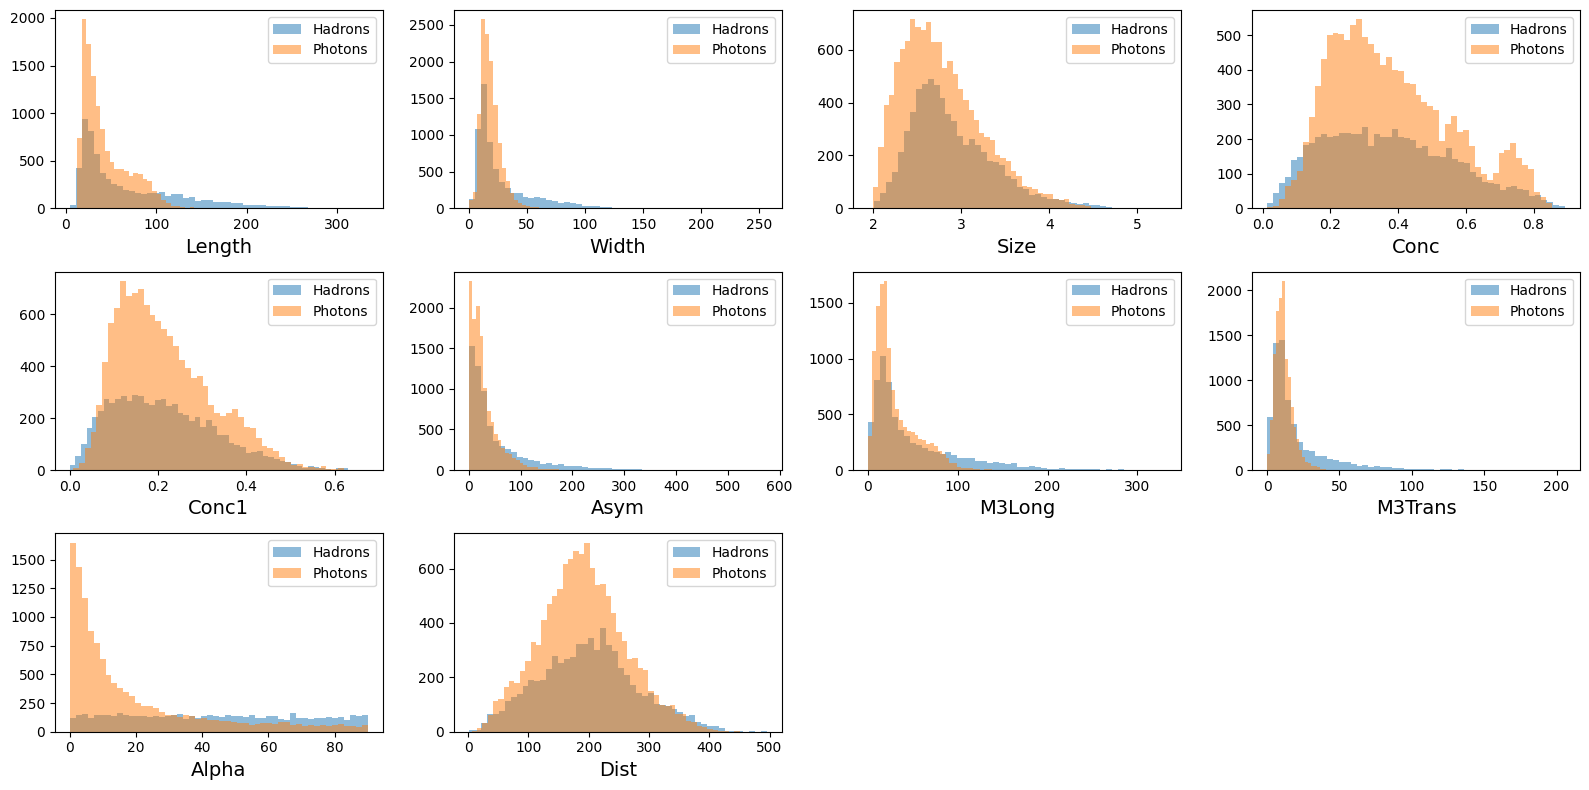

In [8]:
plot_hists(
    X[y[:, 0] == 0], X[y[:, 0] == 1], names, label1="Hadrons", label2="Photons", bins=50
)

# Предобработка данных

Из графика видим, что распределения для многих признаков имеют тяжелые хвосты. Это делает обучение генеративных моделей тяжелее. Поэтому, нужно как-то преобразовать данные, чтобы убрать эти тяжелые хвосты.

## Задание 1 (1 балл)

Используя функцию `sklearn.preprocessing.QuantileTransformer` трансформируйте входные данные `X`. Это преобразование делает так, чтобы распределение каждого параметра было нормальным. Описание функции доступно по ссылке http://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.QuantileTransformer.html. Используйте значение параметра `output_distribution='normal'`.

In [9]:
from sklearn.preprocessing import QuantileTransformer
qt = QuantileTransformer(output_distribution='normal')
X_qt = qt.fit_transform(X)

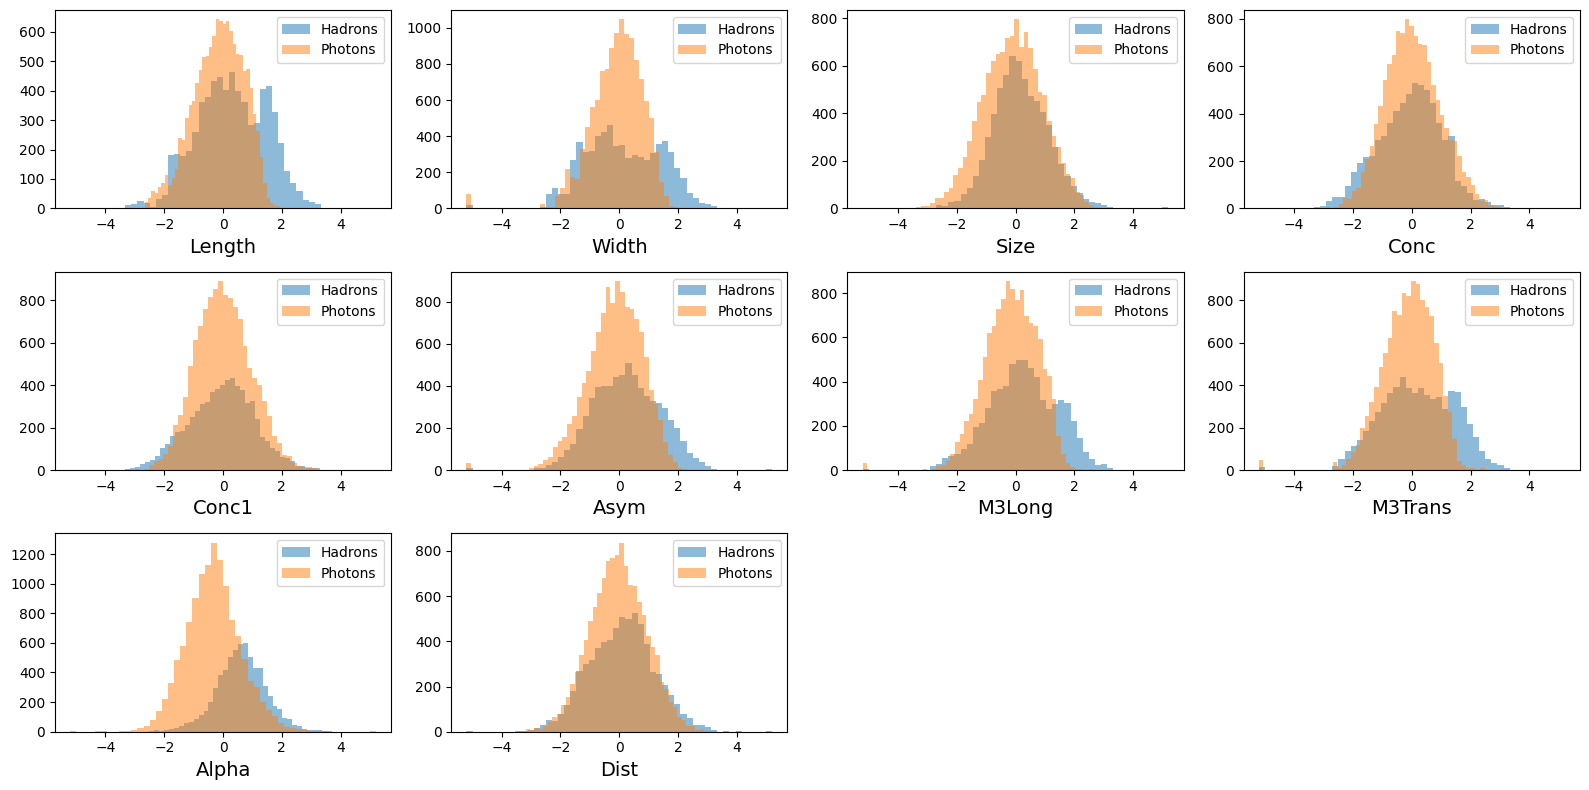

In [10]:
plot_hists(
    X_qt[y[:, 0] == 0],
    X_qt[y[:, 0] == 1],
    names,
    label1="Hadrons",
    label2="Photons",
    bins=50,
)

# Обучающая и тестовая выборки

In [11]:
from sklearn.model_selection import train_test_split

# train / test split
X_train, X_test, y_train, y_test = train_test_split(
    X_qt, y, stratify=y, test_size=0.5, shuffle=True, random_state=11
)

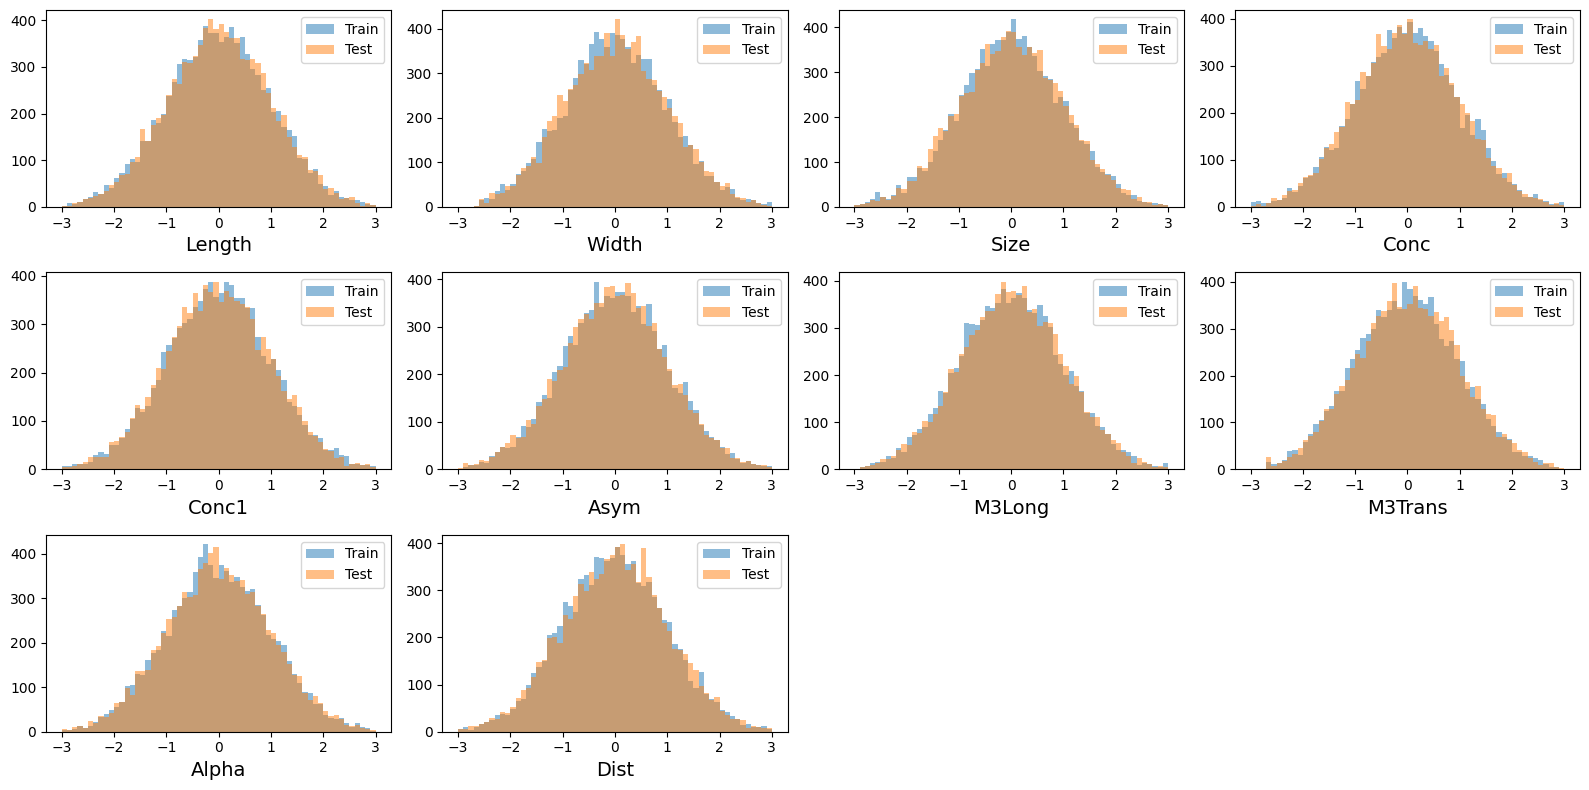

In [12]:
plot_hists(X_train, X_test, names, label1="Train", label2="Test")

# Conditional WGAN

Мы будем использовать `Conditional WGAN`, который изображен на рисунке. В качестве условия `y` мы будем использовать метку класса: **0** - адрон, **1** - фотон. Таким образом, мы будем сообщать генератору для какой частицы нужно генерировать параметры изображения.

<center><img src="https://github.com/just-hw/GEN_HW/blob/main/GEN_HW2/img/cgan.png?raw=1" width="800"></center>

Генератор $\hat{x} = G(z, y)$ будет принимать на вход шумовой вектор $z$ и вектор условий $y$, а выдавать будет сгенерированный (фейковый) вектор параметров $\hat{x}$.

Дискриминатор $D(x, y)$ будет принимать на вход вектор параметров $x$ и вектор условий $y$, а возвращать будет рациональное число.

Обучать `Conditional WGAN` будем с такой функцией потерь:

$$L(G, D) = -\frac{1}{n} \sum_{x_i \in X, y_i \in y} D(x_i, y_i) + -\frac{1}{n} \sum_{z_i \in Z, y_i \in y} D(G(z_i, y_i), y_i) \to \max_G \min_D$$

In [13]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.autograd import Variable
from torch.utils.data import DataLoader, TensorDataset

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [14]:
DEVICE

device(type='cuda')

## Задание 2 (1 балл)

Реализуйте нейронную сеть для генератора со следующими слоями:
- Полносвязный слой со 100 нейронами;
- Слой батч-нормализации;
- ReLU функцию активации;
- Полносвязный слой со 100 нейронами;
- Слой батч-нормализации;
- ReLU функцию активации;
- Выходной слой.

Подсказка: используйте функцию `nn.Sequential()`.

In [15]:
class Generator(nn.Module):
    def __init__(self, n_inputs, n_outputs):
        super(Generator, self).__init__()

        self.net = nn.Sequential(
            nn.Linear(n_inputs, 100),
            nn.BatchNorm1d(100),
            nn.ReLU(),
            nn.Linear(100, 100),
            nn.BatchNorm1d(100),
            nn.ReLU(),
            nn.Linear(100, n_outputs)
        )

    def forward(self, z, y):
        zy = torch.cat((z, y), dim=1)
        return self.net(zy)

## Задание 3 (1 балл)
Реализуйте нейронную сеть для дискриминатора со следующими слоями:
- Полносвязный слой со 100 нейронами;
- ReLU функцию активации;
- Полносвязный слой со 100 нейронами;
- ReLU функцию активации;
- Выходной слой.

Подсказка: используйте функцию `nn.Sequential()`.

In [16]:
class Discriminator(nn.Module):
    def __init__(self, n_inputs):
        super(Discriminator, self).__init__()


        self.net = nn.Sequential(
            nn.Linear(n_inputs, 100),
            nn.ReLU(),
            nn.Linear(100, 100),
            nn.ReLU(),
            nn.Linear(100, 1)
        )


    def forward(self, x, y):
        xy = torch.cat((x, y), dim=1)
        return self.net(xy)

## Задание 4 (2 балла)

Реализуйте класс для обучения генеративной модели.

- Подсказка 1: не забывайте ограничивать веса дискриминатора. Для этого используйте `p.data.clamp_(-0.01, 0.01)`, где `p` веса дискриминатора.
- Подсказка 2: `n_critic` - число итераций обучения дискриминатора на одну итерацию обучения генератора.
- Подсказка 3: Используйте `X_tensor = torch.tensor(X_numpy, dtype=torch.float, device=DEVICE)` для перевода numpy в тензор.

In [17]:
class Fitter(object):
    def __init__(
        self,
        generator,
        discriminator,
        batch_size=32,
        n_epochs=10,
        latent_dim=1,
        lr=0.0001,
        n_critic=5,
    ):

        self.generator = generator
        self.discriminator = discriminator
        self.batch_size = batch_size
        self.n_epochs = n_epochs
        self.latent_dim = latent_dim
        self.lr = lr
        self.n_critic = n_critic

        self.opt_gen = torch.optim.RMSprop(self.generator.parameters(), lr=self.lr)
        self.opt_disc = torch.optim.RMSprop(self.discriminator.parameters(), lr=self.lr)

        self.generator.to(DEVICE)
        self.discriminator.to(DEVICE)

    def fit(self, X, y):

        # numpy to tensor
        X_real = torch.tensor(X, dtype=torch.float, device=DEVICE)
        y_cond = torch.tensor(y, dtype=torch.float, device=DEVICE)

        # tensor to dataset
        dataset_real = TensorDataset(X_real, y_cond)

        # Turn on training
        self.generator.train(True)
        self.discriminator.train(True)

        self.loss_history = []

        # Fit GAN
        for epoch in range(self.n_epochs):
            for i, (real_batch, cond_batch) in enumerate(
                DataLoader(dataset_real, batch_size=self.batch_size, shuffle=True)
            ):

                Z_noise = torch.normal(0, 1, (len(real_batch),
                                              self.latent_dim)).to(DEVICE)
                with torch.no_grad():
                  fake_batch = self.generator(Z_noise, cond_batch)
                fake_score = self.discriminator(fake_batch, cond_batch)
                real_score = self.discriminator(real_batch, cond_batch)
                loss_disc = -(torch.mean(real_score) - torch.mean(fake_score))
                self.opt_disc.zero_grad()
                loss_disc.backward()
                self.opt_disc.step()
                for p in self.discriminator.parameters():
                  p.data.clamp_(-0.01, 0.01)

                if i % self.n_critic == 0:
                  fake_batch = self.generator(Z_noise, cond_batch)
                  fake_score = self.discriminator(fake_batch, cond_batch)
                  loss_gen = -torch.mean(fake_score)
                  self.opt_gen.zero_grad()
                  loss_gen.backward()
                  self.opt_gen.step()


            # caiculate and store loss after an epoch
            Z_noise = torch.normal(0, 1, (len(X_real), self.latent_dim)).to(DEVICE)
            X_fake = self.generator(Z_noise, y_cond)
            loss_epoch = torch.mean(self.discriminator(X_real, y_cond)) - torch.mean(
                self.discriminator(X_fake, y_cond)
            )
            self.loss_history.append(loss_epoch.detach().cpu())

        # Turn off training
        self.generator.train(False)
        self.discriminator.train(False)

## Обучение
Обучим модель на данных.

In [18]:
%%time
latent_dim = 10
generator = Generator(n_inputs=latent_dim + y.shape[1], n_outputs=X_train.shape[1])
discriminator = Discriminator(n_inputs=X_train.shape[1] + y.shape[1])

fitter = Fitter(
    generator,
    discriminator,
    batch_size=50,
    n_epochs=100,
    latent_dim=latent_dim,
    lr=0.0001,
    n_critic=5,
)
fitter.fit(X_train, y_train)

CPU times: user 1min 9s, sys: 1.17 s, total: 1min 10s
Wall time: 1min 13s


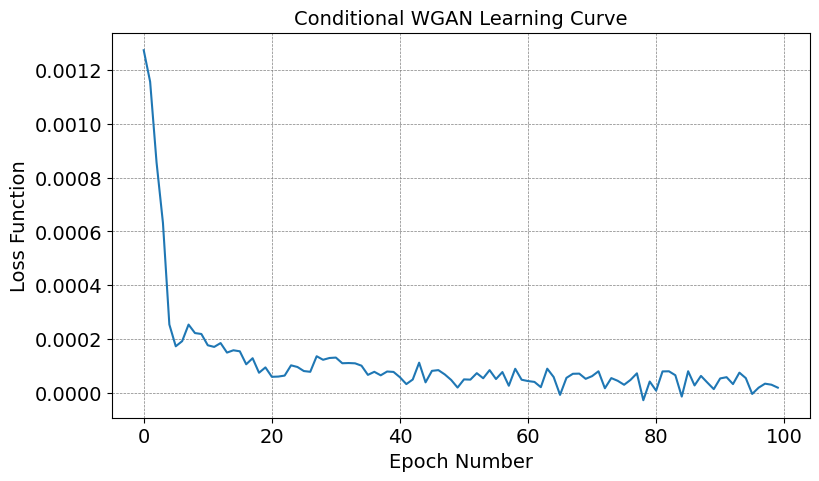

In [19]:
# WGAN learning curve
plt.figure(figsize=(9, 5))
plt.plot(fitter.loss_history)
plt.xlabel("Epoch Number", size=14)
plt.ylabel("Loss Function", size=14)
plt.xticks(size=14)
plt.yticks(size=14)
plt.title("Conditional WGAN Learning Curve", size=14)
plt.grid(visible=True, linestyle="--", linewidth=0.5, color="0.5")
plt.show()

## Задание 5 (1 балл)

Реализуйте функцию для генерации новый объектов $X$ по вектору условий $y$.

In [20]:
def generate(generator, y, latent_dim):
    ### YOUR CODE IS HERE ######
    y = torch.tensor(y, dtype=torch.float, device=DEVICE)
    Z_noise = torch.normal(0, 1, (len(y), latent_dim)).to(DEVICE)
    with torch.no_grad():
        X_fake = generator(Z_noise, y)
    X_fake = X_fake.cpu().numpy()
    ### THE END OF YOUR CODE ###
    return X_fake  # numpy

Теперь сгенерируем фейковые матрицы `X_fake_train` и `X_fake_test`. Сравним их с матрицами реальных объектов `X_train` и `X_test`

In [21]:
X_fake_train = generate(fitter.generator, y_train, latent_dim)

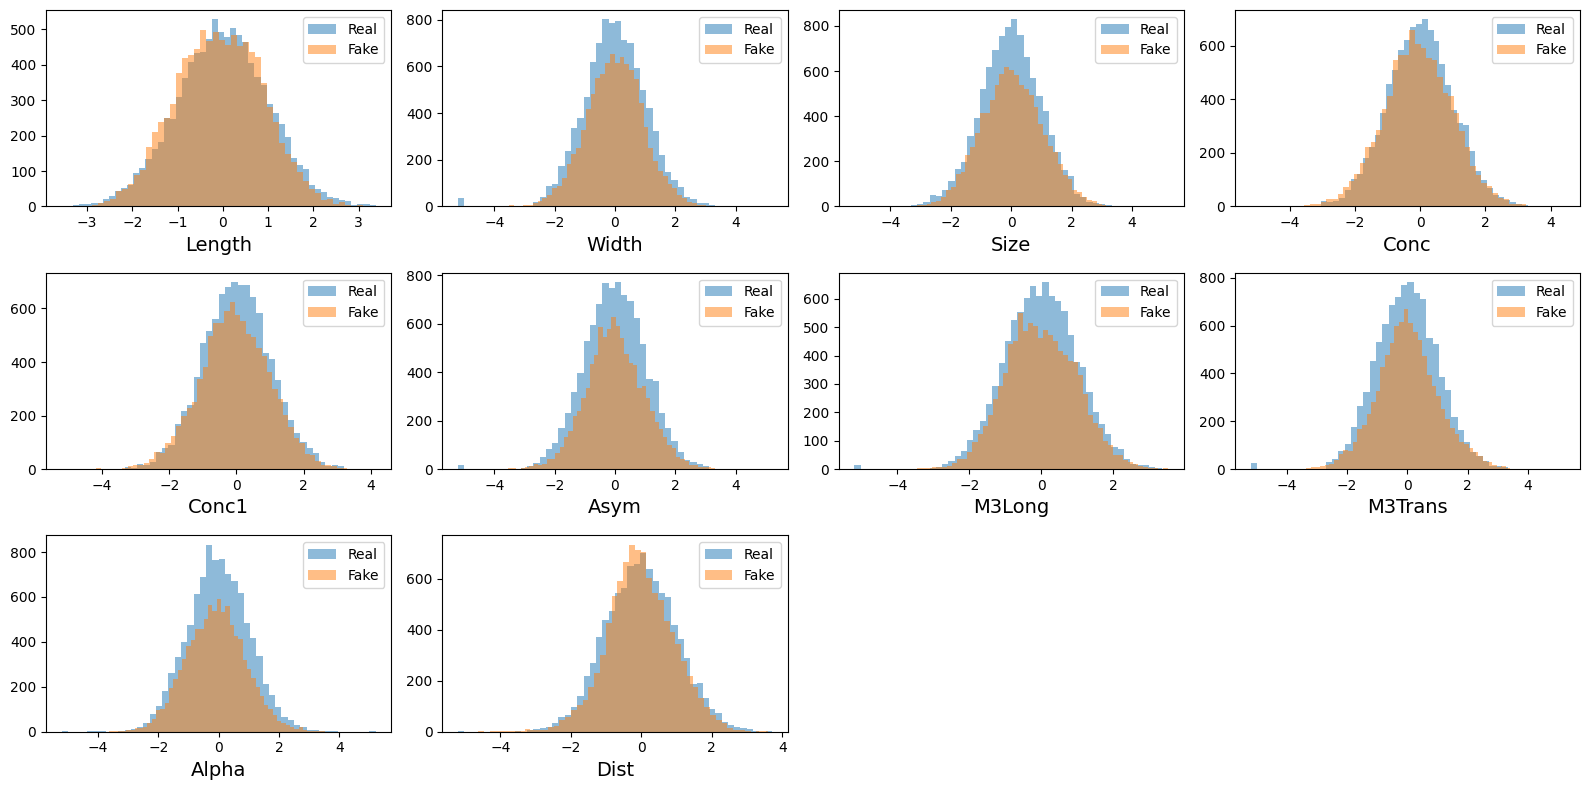

In [22]:
plot_hists(X_train, X_fake_train, names, label1="Real", label2="Fake", bins=50)

In [23]:
X_fake_test = generate(fitter.generator, y_test, latent_dim)

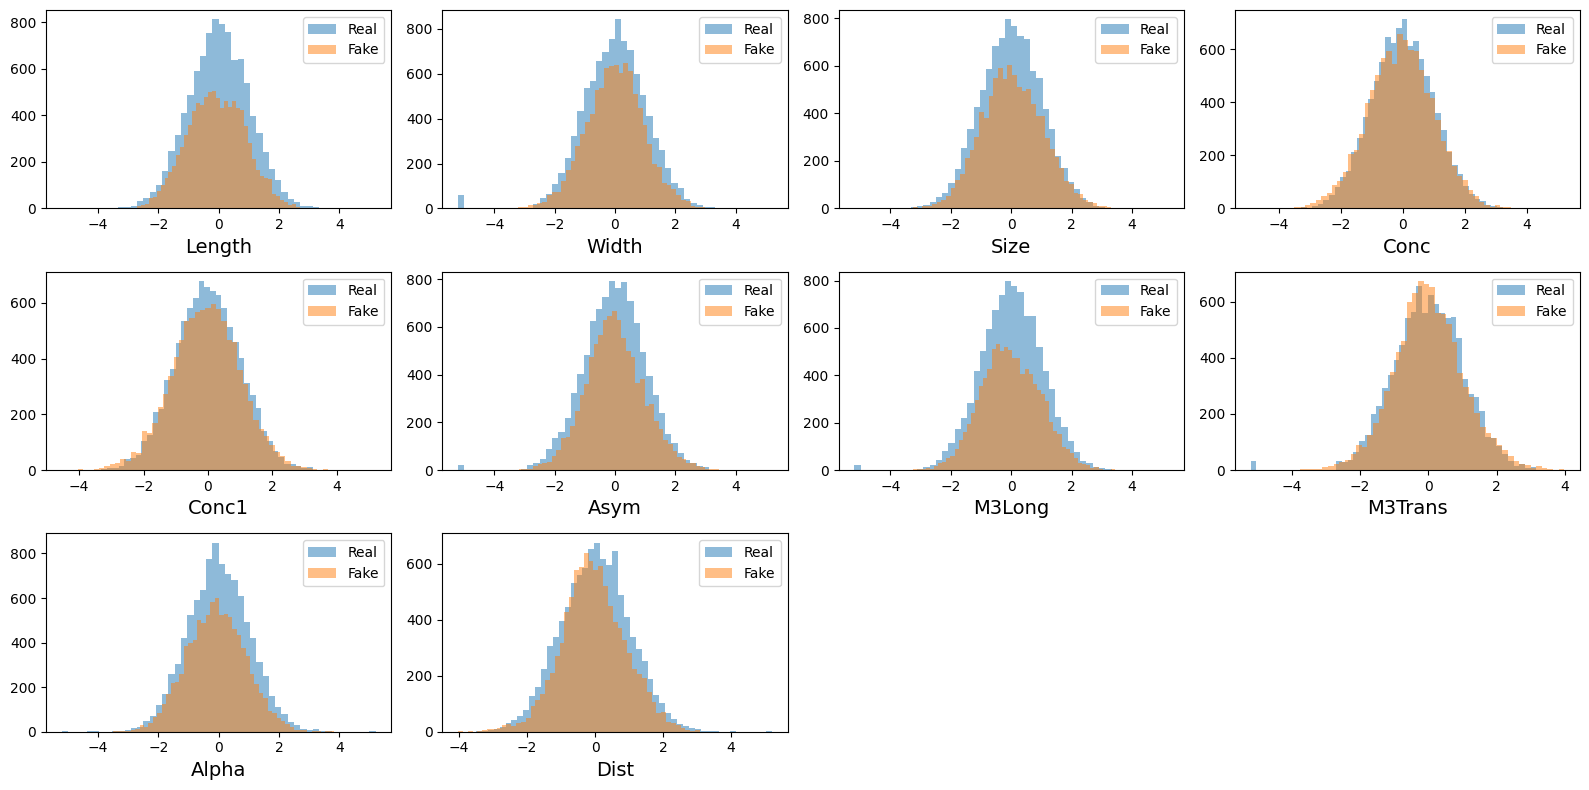

In [24]:
plot_hists(X_test, X_fake_test, names, label1="Real", label2="Fake", bins=50)

## Вывод 1:
Визуально мы видим сходство реальных и фейковых данных. Однако это только проекции 10-мерных объектов на одну ось.

# Измерение качества генерации

<center><img src="https://github.com/just-hw/GEN_HW/blob/main/GEN_HW2/img/clf.png?raw=1" width="600"></center>

Измерим сходство распределений классификатором.

In [25]:
# собираем реальный и фейковые матрицы в одну
XX_train = np.concatenate((X_fake_train, X_train), axis=0)
XX_test = np.concatenate((X_fake_test, X_test), axis=0)

yy_train = np.array([0] * len(X_fake_train) + [1] * len(X_train))
yy_test = np.array([0] * len(X_fake_test) + [1] * len(X_test))

In [26]:
from sklearn.ensemble import GradientBoostingClassifier
# обучаем классификатор
clf = GradientBoostingClassifier()
clf.fit(XX_train, yy_train)

# получаем прогнозы
yy_test_proba = clf.predict_proba(XX_test)[:, 1]

In [27]:
from sklearn.metrics import roc_auc_score

# получаем прогнозы
yy_test_proba = clf.predict_proba(XX_test)[:, 1]
auc = roc_auc_score(yy_test, yy_test_proba)
print("ROC AUC = ", auc)

ROC AUC =  0.7302721525075713


## Вывод 2

Идеальное значение ROC AUC равно 0.5. Это соответствует случаю, когда классификатор не может разделить реальные и фейковые данные. В нашем случае ROC AUC около 0.7, что говорит о том, что есть куда улучшать качество генеративной модели :)

# Условные вариационные автокодировщики

<center><img src="https://github.com/just-hw/GEN_HW/blob/main/GEN_HW2/img/cvae.svg?raw=1" width="600"></center>

Теперь, решим эту же задачу используя условный автокодировщик (CVAE). Пользуясь вашим семинаром по теме вариационных автокодировщиков выполните следующие задания.

## Задание 6 (1 балл)

Реализуйте нейронную сеть для декодеровщика со следующими слоями:
- Полносвязный слой со 100 нейронами;
- Слой батч-нормализации;
- ReLU функцию активации;
- Полносвязный слой со 100 нейронами;
- Слой батч-нормализации;
- ReLU функцию активации;
- Выходной слой для mu; Выходной слой для log_sigma;

Подсказка: используйте функцию `nn.Sequential()`.

In [28]:
class Encoder(nn.Module):
    def __init__(self, n_inputs, lat_size):
        super(Encoder, self).__init__()

        self.enc_net = nn.Sequential(
            nn.Linear(n_inputs, 100),
            nn.BatchNorm1d(100),
            nn.ReLU(),
            nn.Linear(100, 100),
            nn.BatchNorm1d(100),
            nn.ReLU(),
        )

        self.mu = nn.Linear(100, lat_size)
        self.log_sigma = nn.Linear(100, lat_size)

    def forward(self, x, y):
        z = torch.cat((x, y), dim=1)
        z = self.enc_net(z)
        mu = self.mu(z)
        log_sigma = self.log_sigma(z)
        return mu, log_sigma

## Задание 7 (1 балл)

Реализуйте нейронную сеть для декодеровщика со следующими слоями:
- Полносвязный слой со 100 нейронами;
- ReLU функцию активации;
- Полносвязный слой со 100 нейронами;
- ReLU функцию активации;
- Выходной слой.

Подсказка: используйте функцию `nn.Sequential()`.

In [29]:
class Decoder(nn.Module):
    def __init__(self, n_inputs, n_outputs):
        super(Decoder, self).__init__()

        ### YOUR CODE IS HERE ######
        self.dec_net = nn.Sequential(
            nn.Linear(n_inputs, 100),
            nn.ReLU(),
            nn.Linear(100, 100),
            nn.ReLU(),
            nn.Linear(100, n_outputs)
        )
        ### THE END OF YOUR CODE ###

    def forward(self, z, y):
        z_cond = torch.cat((z, y), dim=1)
        x_rec = self.dec_net(z_cond)
        return x_rec

## Задание 8 (1 балл)

Реализуйте класс для обучения вариационного автокодировщика.

Подсказка: Используйте `X_tensor = torch.tensor(X_numpy, dtype=torch.float, device=DEVICE)` для перевода numpy в тензор.

In [30]:
class VAEFitter(object):
    def __init__(
        self,
        encoder,
        decoder,
        batch_size=32,
        n_epochs=10,
        latent_dim=1,
        lr=0.0001,
        KL_weight=0.001,
    ):

        self.encoder = encoder
        self.decoder = decoder
        self.batch_size = batch_size
        self.n_epochs = n_epochs
        self.latent_dim = latent_dim
        self.lr = lr
        self.KL_weight = KL_weight

        self.criterion = nn.MSELoss()
        self.opt = torch.optim.RMSprop(
            list(self.encoder.parameters()) + list(self.decoder.parameters()),
            lr=self.lr,
        )

        self.encoder.to(DEVICE)
        self.decoder.to(DEVICE)

    def sample_z(self, mu, log_sigma):
        eps = torch.randn(mu.shape).to(DEVICE)
        return mu + torch.exp(log_sigma / 2) * eps

    def custom_loss(self, x, rec_x, mu, log_sigma):
        KL = torch.mean(
            -0.5 * torch.sum(1 + log_sigma - mu**2 - log_sigma.exp(), dim=1), dim=0
        )
        recon_loss = self.criterion(x, rec_x)
        return KL * self.KL_weight + recon_loss

    def compute_loss(self, x_batch, cond_batch):

        ### YOUR CODE IS HERE ######
        rec_mu, rec_log_sigma = self.encoder(x_batch, cond_batch)
        z = self.sample_z(rec_mu, rec_log_sigma)
        rec_batch = self.decoder(z, cond_batch)
        loss = self.custom_loss(x_batch, rec_batch, rec_mu, rec_log_sigma)
        ### THE END OF YOUR CODE ###

        return loss

    def fit(self, X, y):

        # numpy to tensor
        X_real = torch.tensor(X, dtype=torch.float, device=DEVICE)
        y_cond = torch.tensor(y, dtype=torch.float, device=DEVICE)

        # tensor to dataset
        dataset_real = TensorDataset(X_real, y_cond)

        # Turn on training
        self.encoder.train(True)
        self.decoder.train(True)

        self.loss_history = []

        # Fit GAN
        for epoch in range(self.n_epochs):
            for i, (x_batch, cond_batch) in enumerate(
                DataLoader(dataset_real, batch_size=self.batch_size, shuffle=True)
            ):

                # caiculate loss
                loss = self.compute_loss(x_batch, cond_batch)

                # optimization step
                self.opt.zero_grad()
                loss.backward()
                self.opt.step()

            # caiculate and store loss after an epoch
            loss_epoch = self.compute_loss(X_real, y_cond)
            self.loss_history.append(loss_epoch.detach().cpu())

        # Turn off training
        self.encoder.train(False)
        self.decoder.train(False)

## Обучение
Обучим модель на данных.

In [31]:
%%time

latent_dim = 10

encoder = Encoder(n_inputs=X_train.shape[1] + y.shape[1], lat_size=latent_dim)
decoder = Decoder(n_inputs=latent_dim + y.shape[1], n_outputs=X_train.shape[1])

vae_fitter = VAEFitter(
    encoder,
    decoder,
    batch_size=50,
    n_epochs=100,
    latent_dim=latent_dim,
    lr=0.001,
    KL_weight=0.001,
)
vae_fitter.fit(X_train, y_train)

CPU times: user 1min 9s, sys: 909 ms, total: 1min 10s
Wall time: 1min 11s


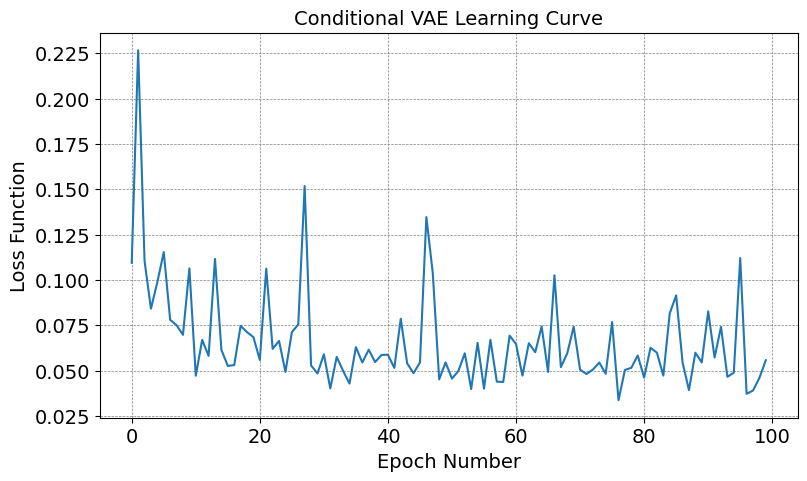

In [33]:
# WGAN learning curve
plt.figure(figsize=(9, 5))
plt.plot(vae_fitter.loss_history)
plt.xlabel("Epoch Number", size=14)
plt.ylabel("Loss Function", size=14)
plt.xticks(size=14)
plt.yticks(size=14)
plt.title("Conditional VAE Learning Curve", size=14)
plt.grid(visible=True, linestyle="--", linewidth=0.5, color="0.5")
plt.show()

## Задание 9 (1 балл)

Реализуйте функцию для генерации новый объектов $X$ по вектору условий $y$.

In [34]:
def generate(decoder, y, latent_dim):
    ### YOUR CODE IS HERE ######
    y = torch.tensor(y, dtype=torch.float, device=DEVICE)
    z = torch.randn(len(y), latent_dim, device=DEVICE)
    decoder.eval()
    with torch.no_grad():
        X_fake = decoder(z, y)
    X_fake = X_fake.cpu().numpy()
    ### THE END OF YOUR CODE ###
    return X_fake  # numpy

Теперь сгенерируем фейковые матрицы `X_fake_train` и `X_fake_test`. Сравним их с матрицами реальных объектов `X_train` и `X_test`

In [35]:
X_fake_train = generate(vae_fitter.decoder, y_train, latent_dim)

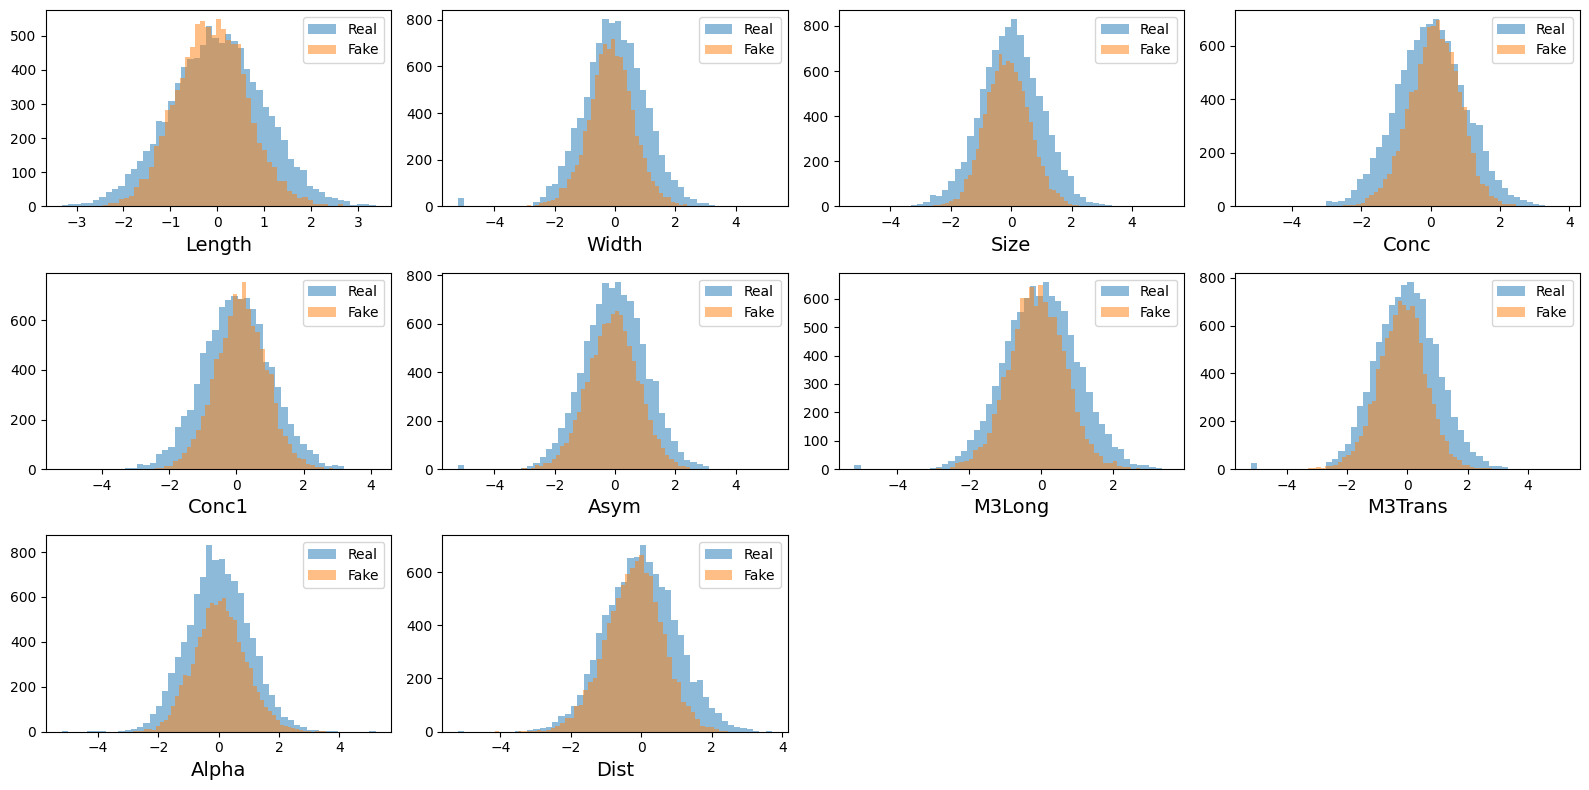

In [36]:
plot_hists(X_train, X_fake_train, names, label1="Real", label2="Fake", bins=50)

In [37]:
X_fake_test = generate(vae_fitter.decoder, y_test, latent_dim)

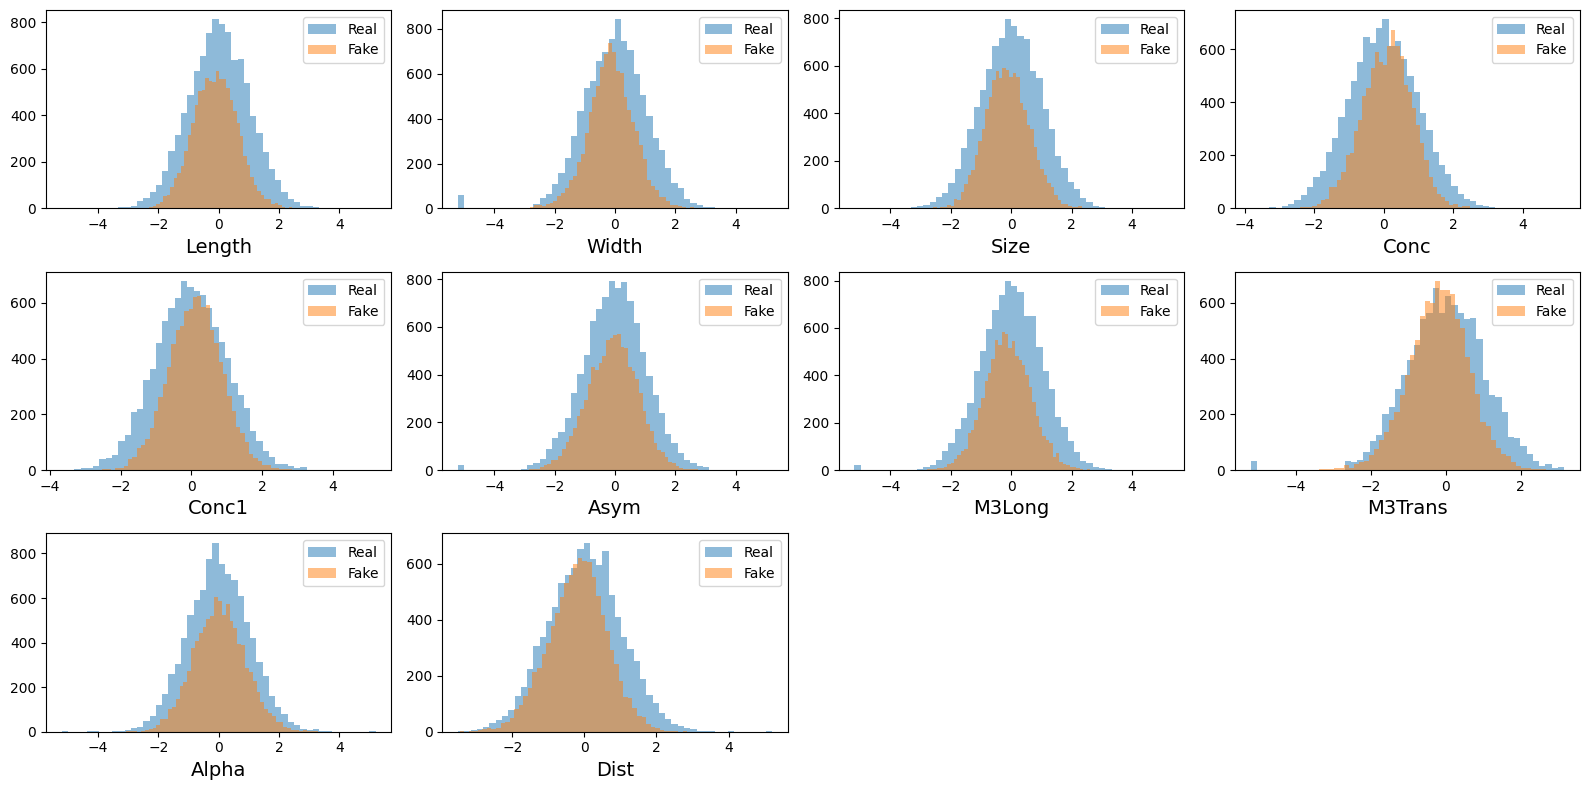

In [38]:
plot_hists(X_test, X_fake_test, names, label1="Real", label2="Fake", bins=50)

# Измерение качества генерации

Измерим сходство распределений классификатором.

In [39]:
# собираем реальный и фейковые матрицы в одну
XX_train = np.concatenate((X_fake_train, X_train), axis=0)
XX_test = np.concatenate((X_fake_test, X_test), axis=0)

yy_train = np.array([0] * len(X_fake_train) + [1] * len(X_train))
yy_test = np.array([0] * len(X_fake_test) + [1] * len(X_test))

In [40]:
from sklearn.ensemble import GradientBoostingClassifier

# обучаем классификатор
clf = GradientBoostingClassifier()
clf.fit(XX_train, yy_train)

# получаем прогнозы
yy_test_proba = clf.predict_proba(XX_test)[:, 1]

In [41]:
from sklearn.metrics import roc_auc_score

auc = roc_auc_score(yy_test, yy_test_proba)
print("ROC AUC = ", auc)

ROC AUC =  0.7178727356559756


## Вывод 3

Для CVAE получили ROC AUC около 0.7 (меньше лучше). Таким образом видим, что в данной задаче обе модели ведут себя схожим образом. Но может их можно как-то улучшить? Или есть какая-то еще модель? :)

<center><img src="https://github.com/just-hw/GEN_HW/blob/main/GEN_HW2/img/mem1.jpg?raw=1" width="500"></center>

<center><img src="https://github.com/just-hw/GEN_HW/blob/main/GEN_HW2/img/mem2.jpg?raw=1" width="500"></center>

# Бонус (0 баллов)

Попробуйте настроить параметры обучения каждой модели или еще как-нибудь их улучшить, чтобы получить как можно меньший ROC AUC. Что получилось? Какая модель лучше?

## VAE

### Подготовка к экспериментам

In [47]:
class Encoder(nn.Module):
    def __init__(self, n_inputs, lat_size, inner_dim=100):
        super(Encoder, self).__init__()

        self.enc_net = nn.Sequential(
            nn.Linear(n_inputs, inner_dim),
            nn.BatchNorm1d(inner_dim),
            nn.ReLU(),
            nn.Linear(inner_dim, inner_dim),
            nn.BatchNorm1d(inner_dim),
            nn.ReLU(),
        )

        self.mu = nn.Linear(inner_dim, lat_size)
        self.log_sigma = nn.Linear(inner_dim, lat_size)

    def forward(self, x, y):
        z = torch.cat((x, y), dim=1)
        z = self.enc_net(z)
        mu = self.mu(z)
        log_sigma = self.log_sigma(z)
        return mu, log_sigma
class Decoder(nn.Module):
    def __init__(self, n_inputs, n_outputs, inner_dim=100):
        super(Decoder, self).__init__()
        self.dec_net = nn.Sequential(
            nn.Linear(n_inputs, inner_dim),
            nn.ReLU(),
            nn.Linear(inner_dim, inner_dim),
            nn.ReLU(),
            nn.Linear(inner_dim, n_outputs)
        )

    def forward(self, z, y):
        z_cond = torch.cat((z, y), dim=1)
        x_rec = self.dec_net(z_cond)
        return x_rec

In [50]:
def eval_roc_auc(X_train, X_fake_train, X_test, X_fake_test):
  XX_train = np.concatenate((X_fake_train, X_train), axis=0)
  XX_test = np.concatenate((X_fake_test, X_test), axis=0)

  yy_train = np.array([0] * len(X_fake_train) + [1] * len(X_train))
  yy_test = np.array([0] * len(X_fake_test) + [1] * len(X_test))

  clf = GradientBoostingClassifier()
  clf.fit(XX_train, yy_train)

  yy_test_proba = clf.predict_proba(XX_test)[:, 1]

  auc = roc_auc_score(yy_test, yy_test_proba)
  print("ROC AUC = ", auc)
  return auc

def generate(decoder, y, latent_dim):
    y = torch.tensor(y, dtype=torch.float, device=DEVICE)
    z = torch.randn(len(y), latent_dim, device=DEVICE)
    decoder.eval()
    with torch.no_grad():
        X_fake = decoder(z, y)
    X_fake = X_fake.cpu().numpy()
    return X_fake

def run_vae_experiment(config):
  # fitting
  latent_dim = config['latent_dim']
  encoder = Encoder(n_inputs=X_train.shape[1] + y.shape[1],
                    lat_size=latent_dim,
                    inner_dim=config['inner_dim'])
  decoder = Decoder(n_inputs=latent_dim + y.shape[1],
                    n_outputs=X_train.shape[1],
                    inner_dim=config['inner_dim'])
  vae_fitter = VAEFitter(
      encoder,
      decoder,
      batch_size=config['batch_size'],
      n_epochs=config['n_epochs'],
      latent_dim=latent_dim,
      lr=config['lr'],
      KL_weight=config['KL_weight'],
  )
  vae_fitter.fit(X_train, y_train)

  # plot
  plt.figure(figsize=(9, 5))
  plt.plot(vae_fitter.loss_history)
  plt.xlabel("Epoch Number", size=14)
  plt.ylabel("Loss Function", size=14)
  plt.xticks(size=14)
  plt.yticks(size=14)
  plt.title("Conditional VAE Learning Curve", size=14)
  plt.grid(visible=True, linestyle="--", linewidth=0.5, color="0.5")
  plt.show()

  # generate fake data
  X_fake_train = generate(vae_fitter.decoder, y_train,
                          config['latent_dim'])
  plot_hists(X_train, X_fake_train, names, label1="Real", label2="Fake", bins=50)
  X_fake_test = generate(vae_fitter.decoder, y_test,
                         config['latent_dim'])
  plot_hists(X_test, X_fake_test, names, label1="Real", label2="Fake", bins=50)

  # evaluate fake data
  auc = eval_roc_auc(X_train, X_fake_train, X_test, X_fake_test)

  result = config.copy()
  result['auc'] = auc
  return result

In [49]:
base_config={
    'latent_dim': 10,
    'inner_dim': 100,
    'batch_size': 50,
    'n_epochs': 100,
    'lr': 0.001,
    'KL_weight': 0.001
}

In [55]:
import random
import numpy as np
import torch

seed = 42

random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)

results=[
  {
  'latent_dim': 10,
  'inner_dim': 100,
  'batch_size': 50,
  'n_epochs': 100,
  'lr': 0.001,
  'KL_weight': 0.001,
  'auc': np.float64(0.7178727356559756)
  }
]

### Эксперименты

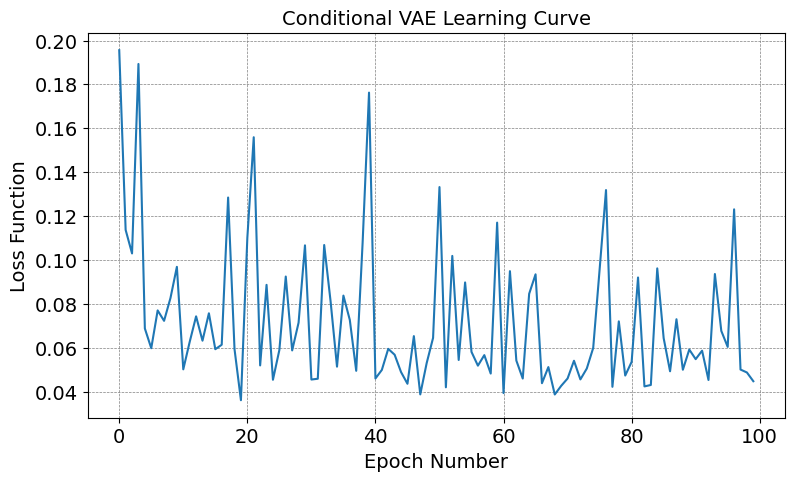

ROC AUC =  0.719818725322064
CPU times: user 1min 24s, sys: 911 ms, total: 1min 25s
Wall time: 1min 26s


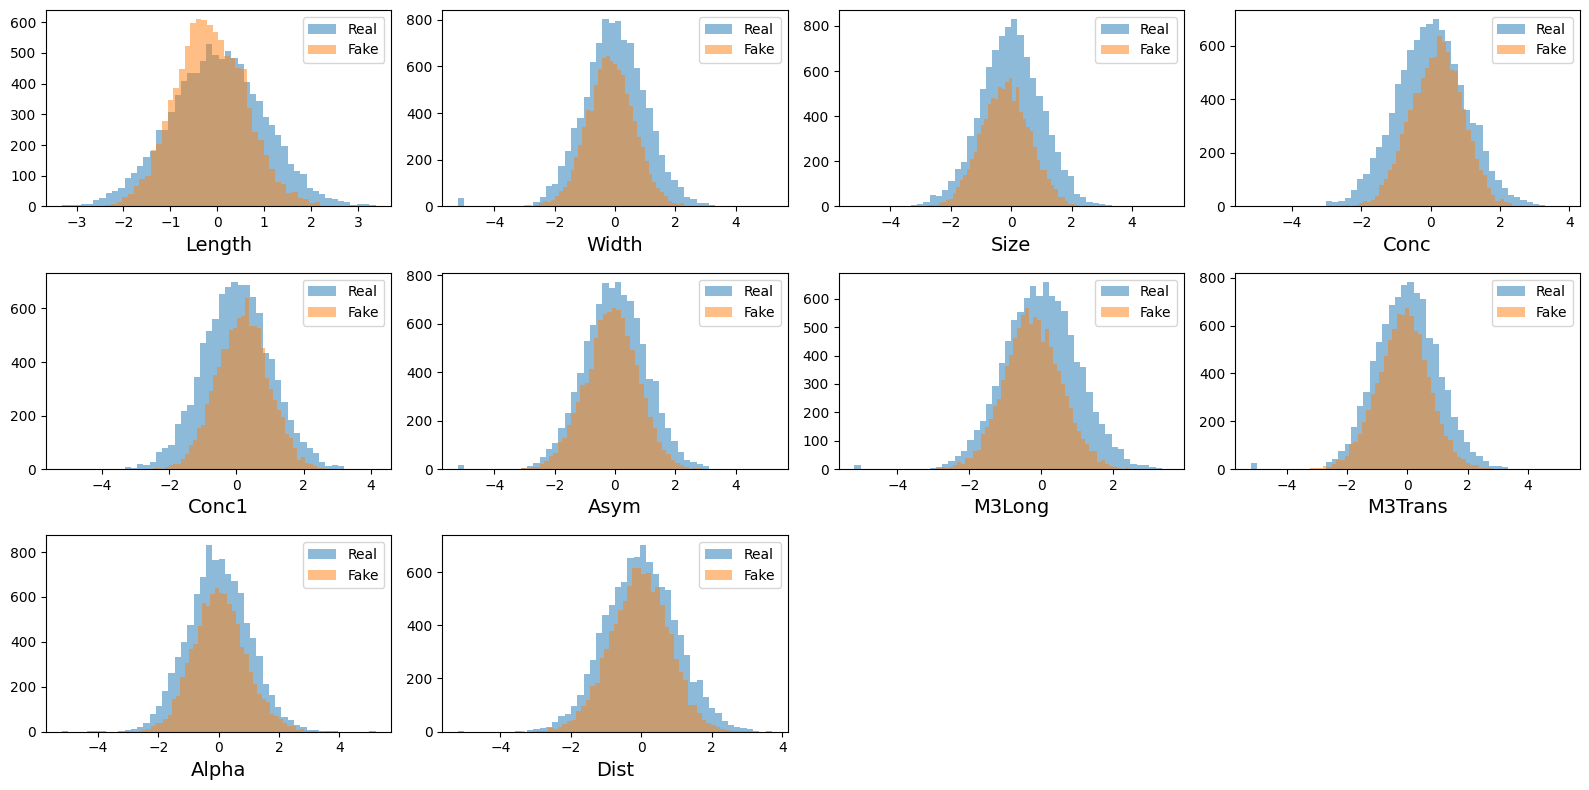

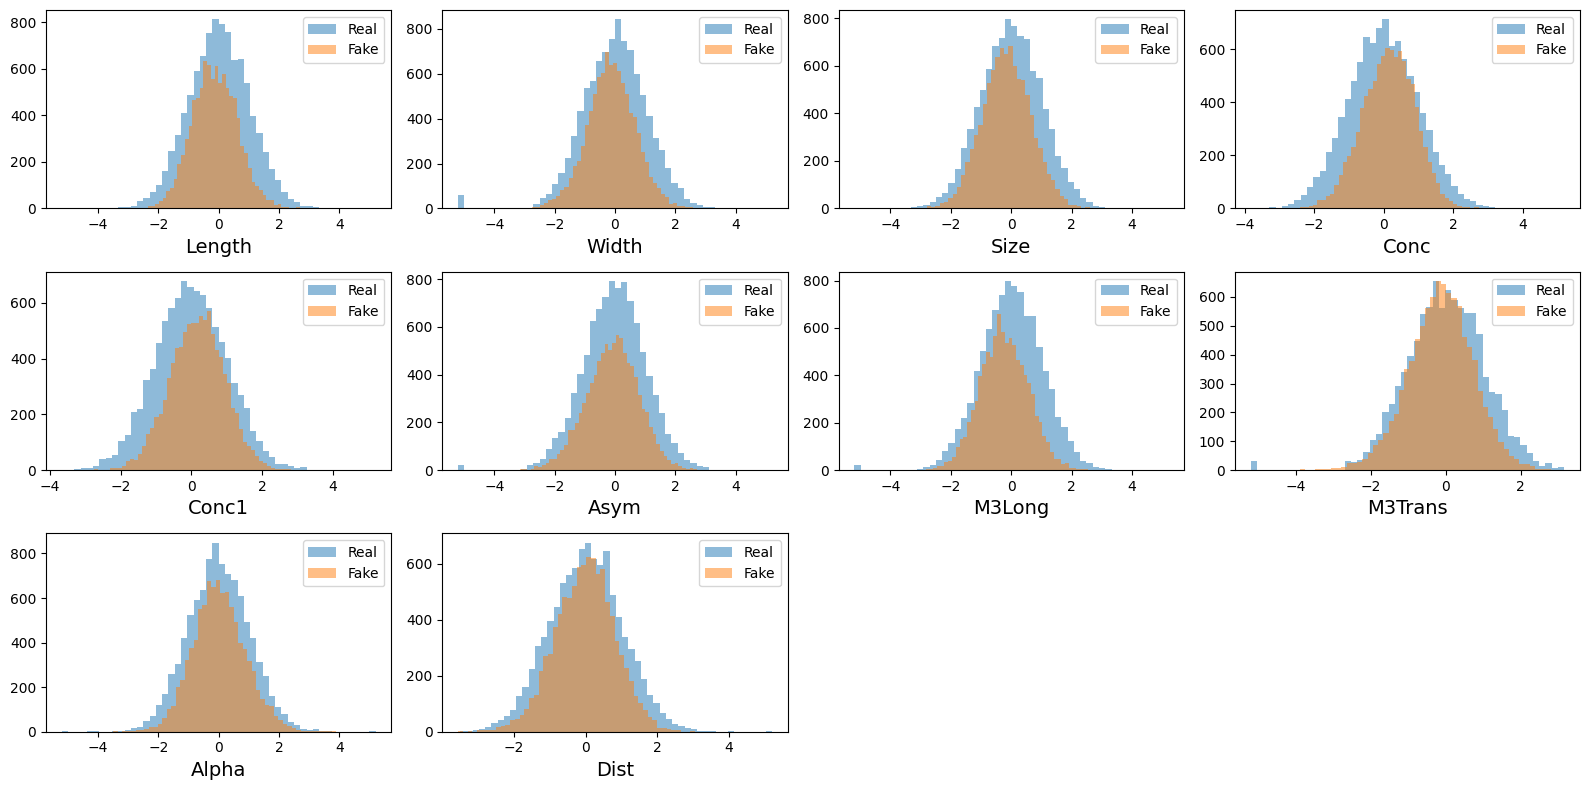

In [51]:
%%time
results.append(run_vae_experiment(config={
    'latent_dim': 10,
    'inner_dim': 150,
    'batch_size': 50,
    'n_epochs': 100,
    'lr': 0.001,
    'KL_weight': 0.001
}))

In [ ]:
%%time
results.append(run_vae_experiment(config={
    'latent_dim': 10,
    'inner_dim': 150,
    'batch_size': 50,
    'n_epochs': 100,
    'lr': 0.001,
    'KL_weight': 0.001
}))

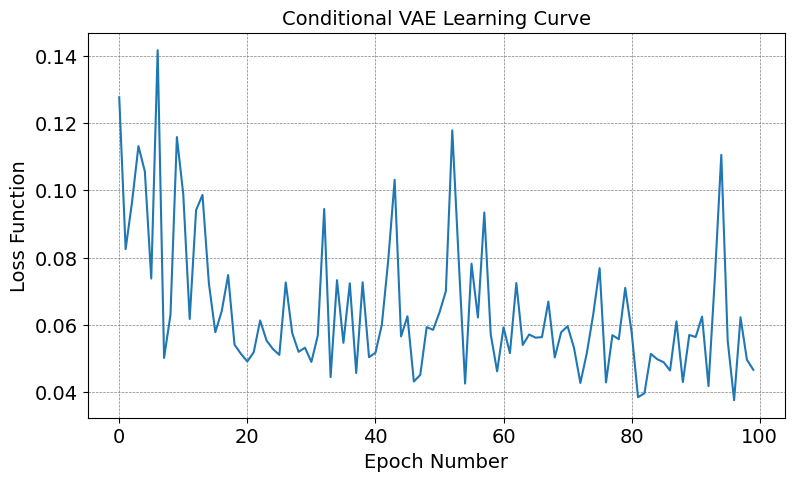

ROC AUC =  0.7357035098368976
CPU times: user 1min 28s, sys: 812 ms, total: 1min 28s
Wall time: 1min 37s


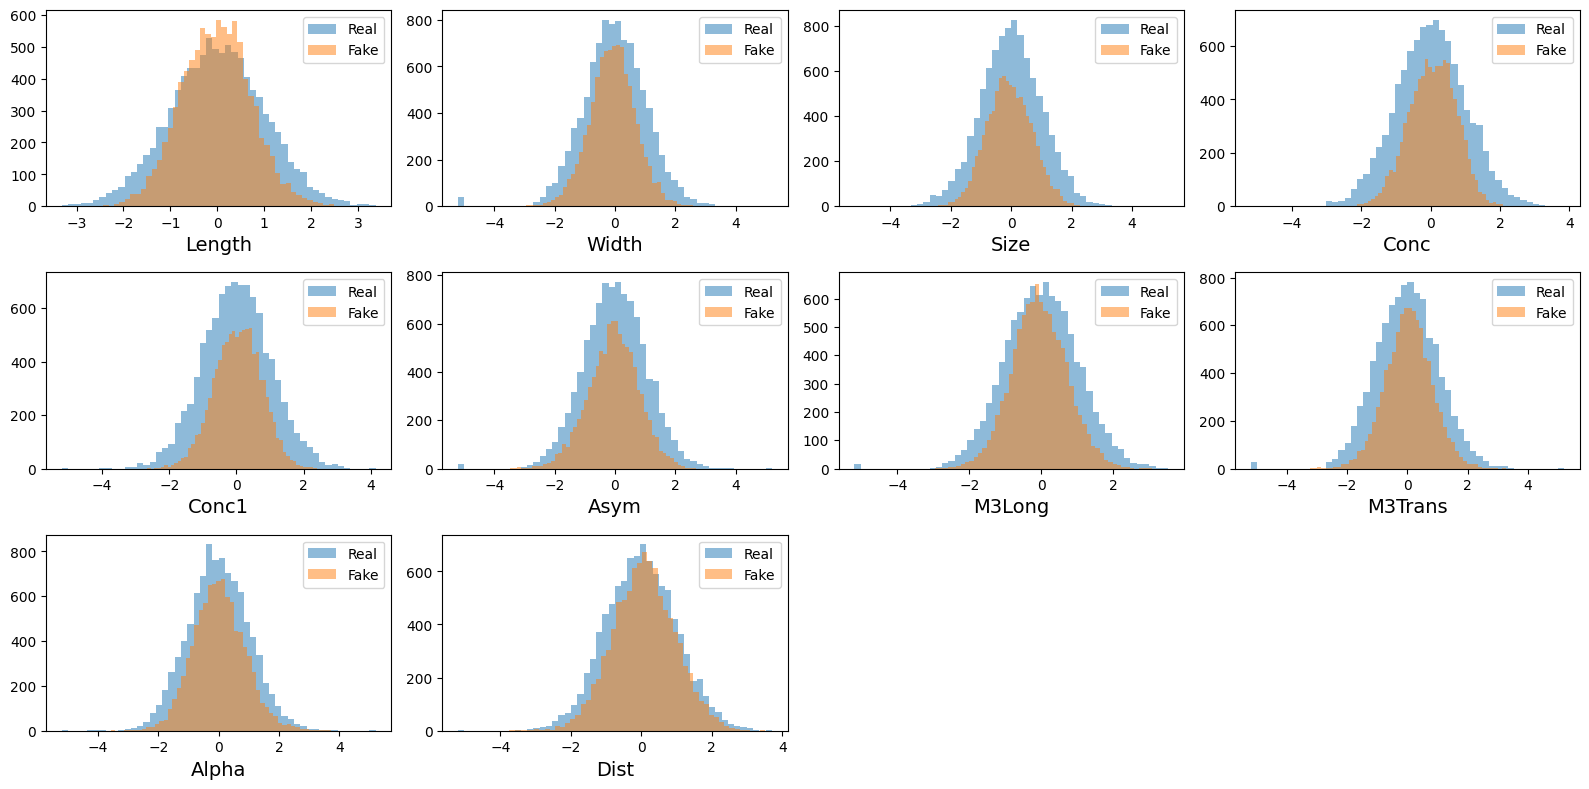

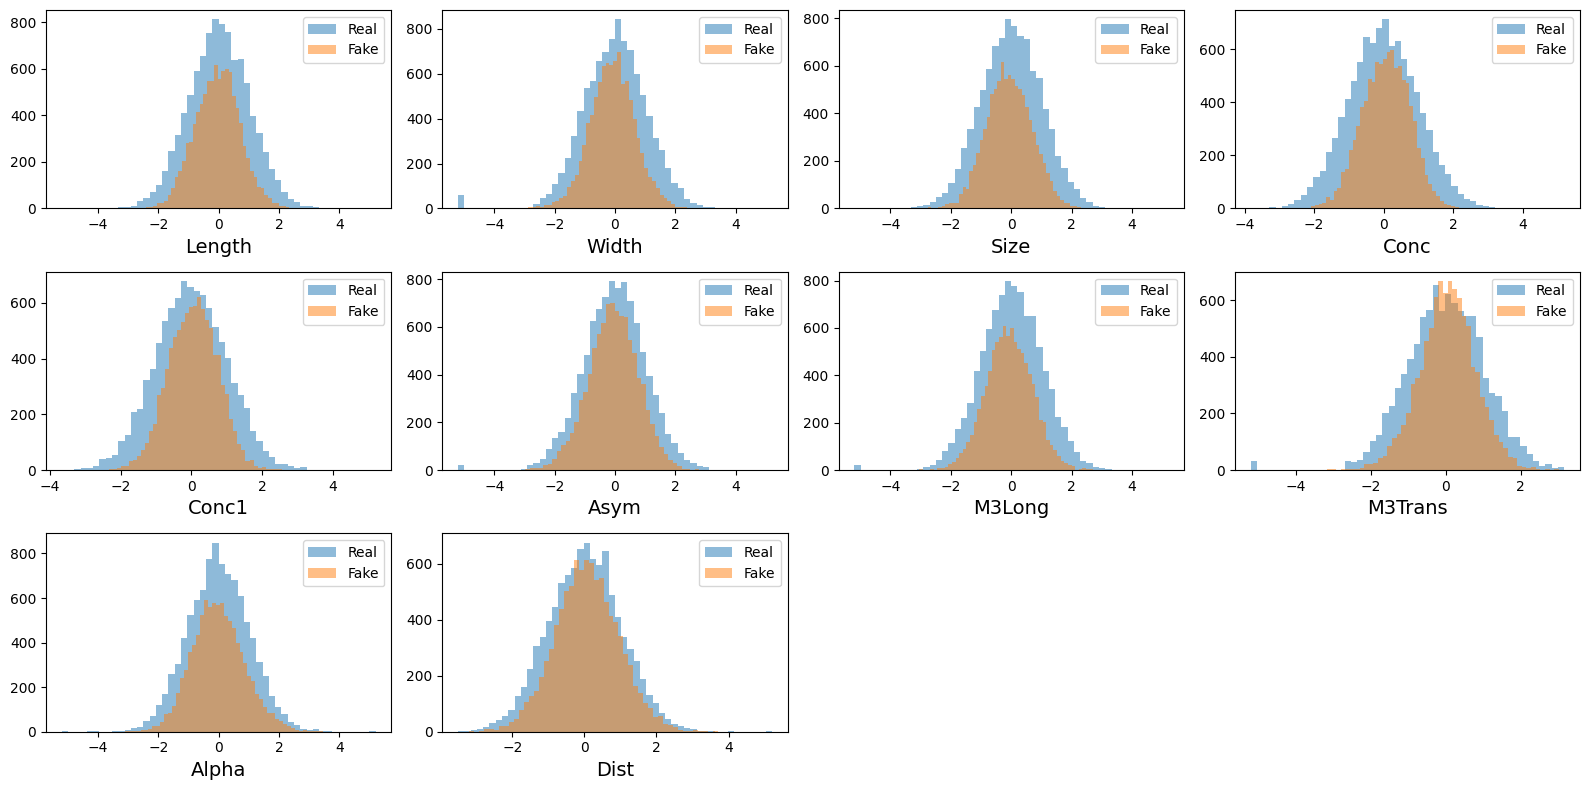

In [57]:
# увеличение числа нейронов в нейросети дало ухудшение метрики
# попробуем поменять latent_dim (размерность скрытого вектор представления)
%%time
results.append(run_vae_experiment(config={
    'latent_dim': 15,
    'inner_dim': 100,
    'batch_size': 50,
    'n_epochs': 100,
    'lr': 0.001,
    'KL_weight': 0.001
}))

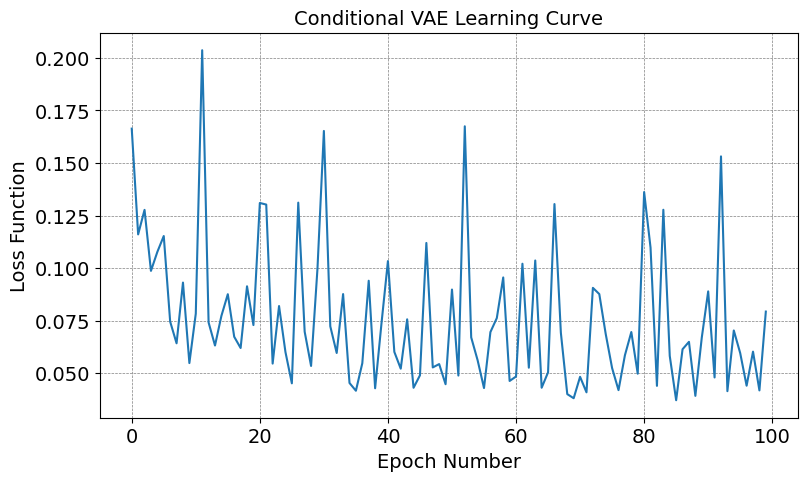

ROC AUC =  0.7346511613764248
CPU times: user 1min 28s, sys: 854 ms, total: 1min 29s
Wall time: 1min 33s


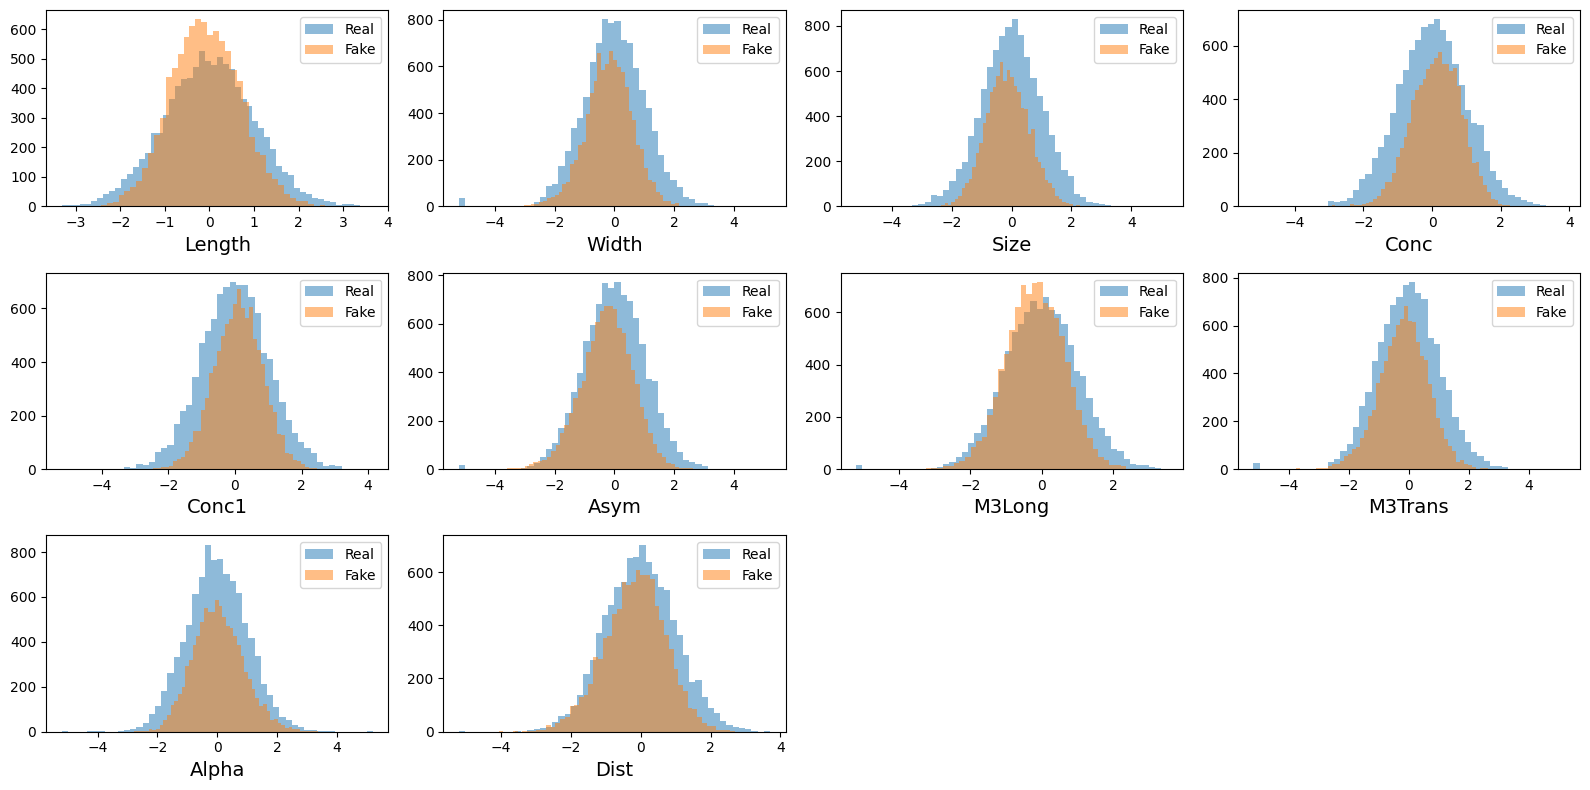

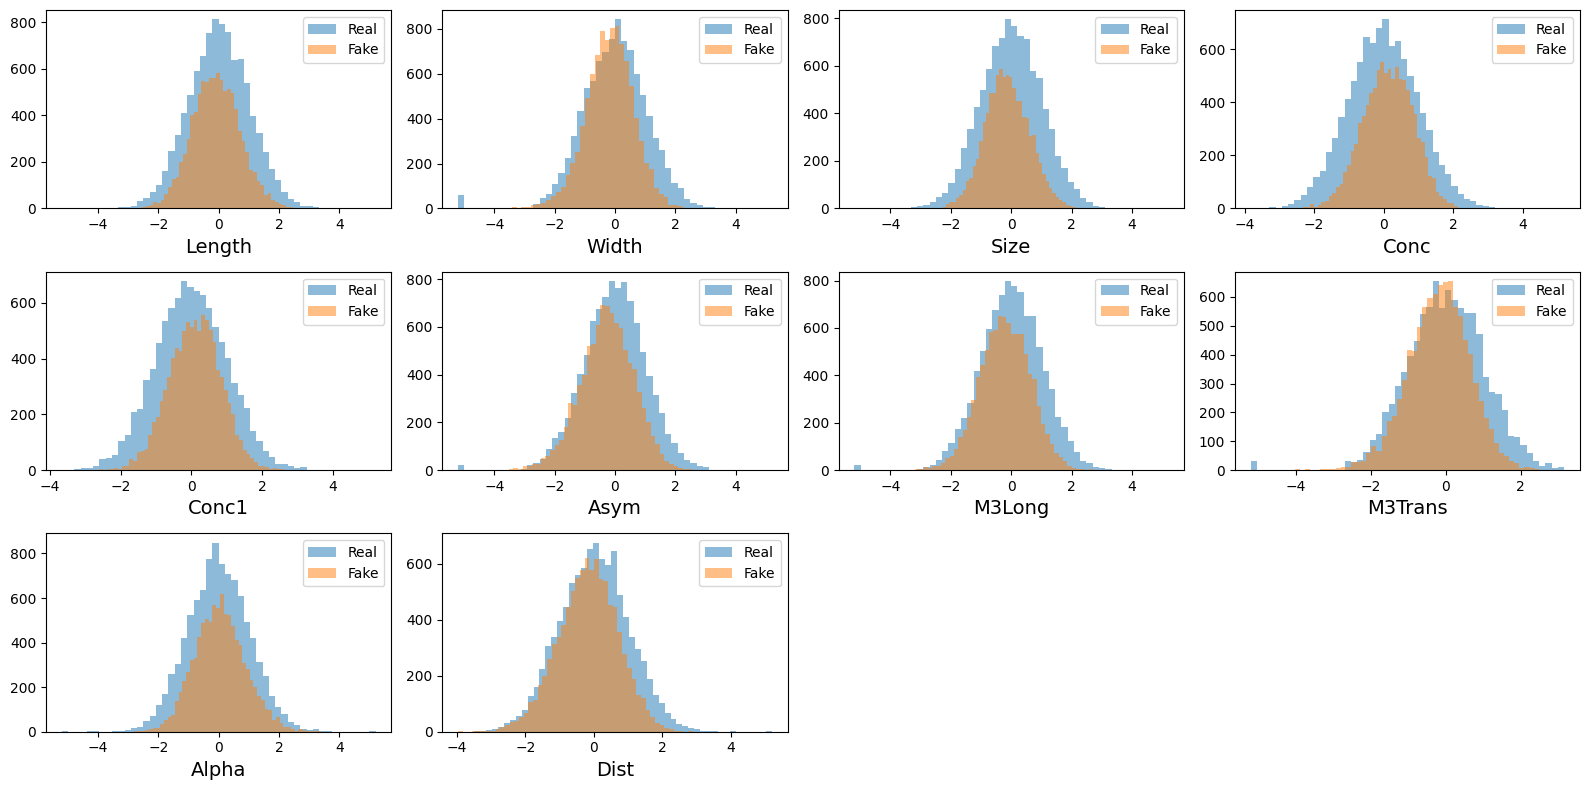

In [59]:
# изменение latent_dim еще сильнее ухудшило
# попробую изменить и latent_dim и inner_dim
%%time
results.append(run_vae_experiment(config={
    'latent_dim': 15,
    'inner_dim': 150,
    'batch_size': 50,
    'n_epochs': 100,
    'lr': 0.001,
    'KL_weight': 0.001
}))

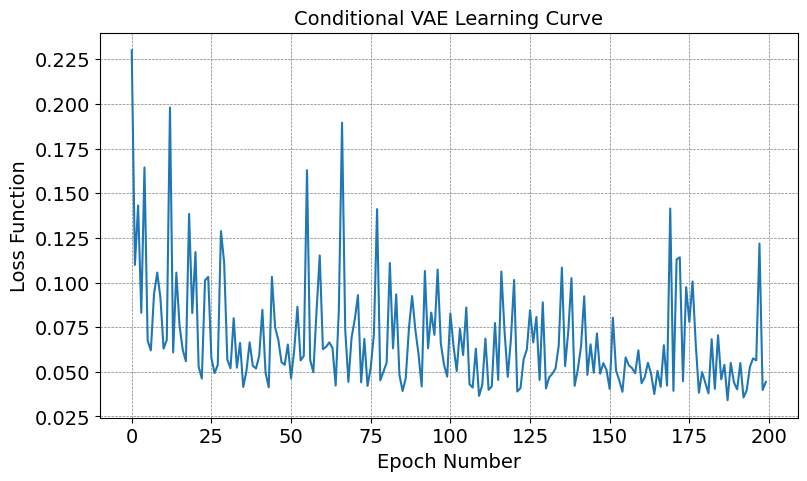

ROC AUC =  0.6779231281256877
CPU times: user 2min 35s, sys: 1.74 s, total: 2min 37s
Wall time: 2min 38s


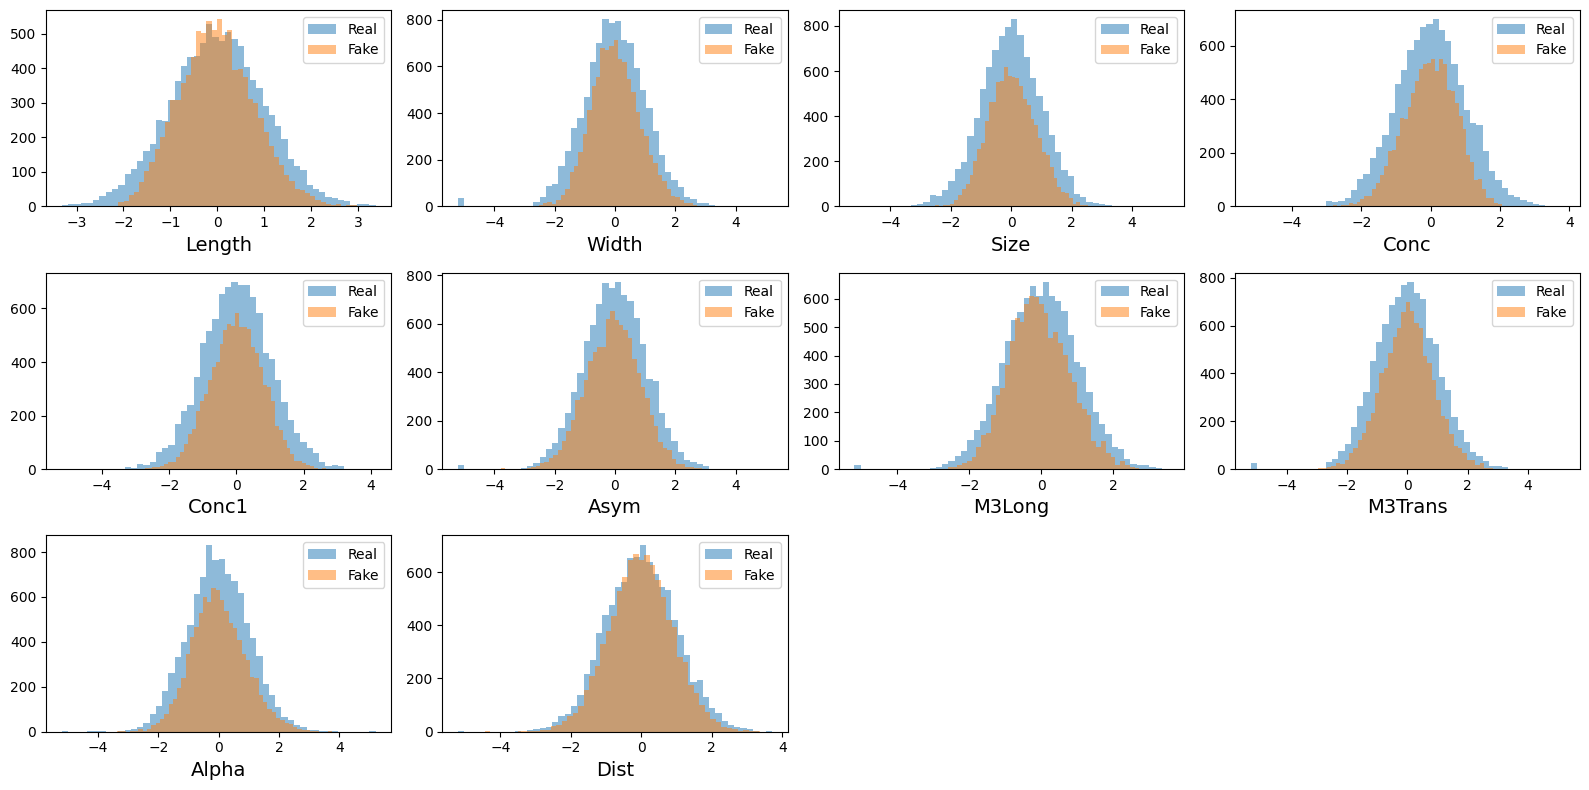

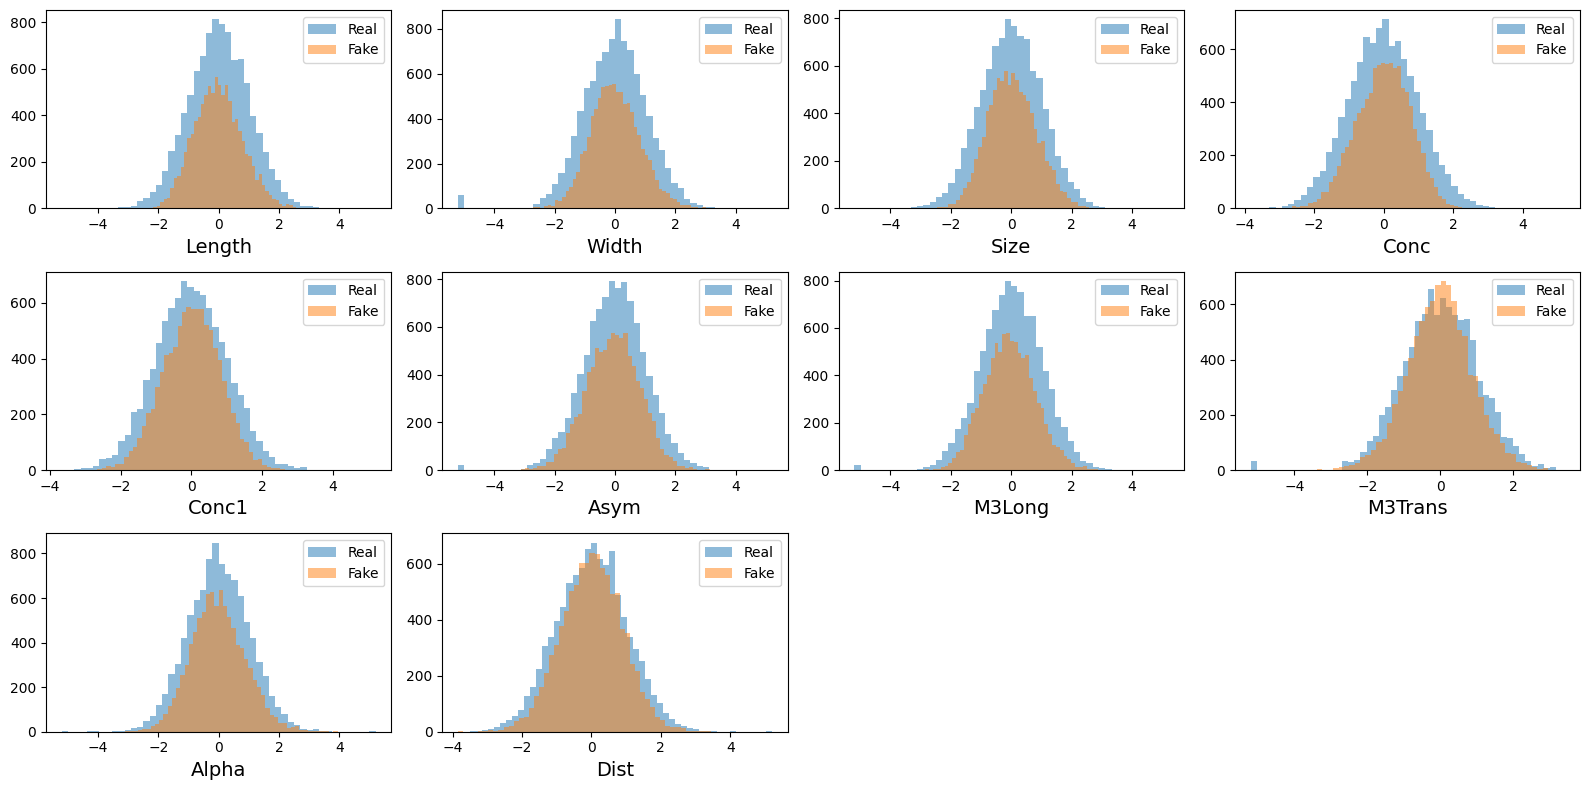

In [61]:
# оставим архитектуру оригинальной и поменяем параметры обучения
%%time
results.append(run_vae_experiment(config={
    'latent_dim': 10,
    'inner_dim': 100,
    'batch_size': 50,
    'n_epochs': 200,
    'lr': 0.002,
    'KL_weight': 0.001
}))

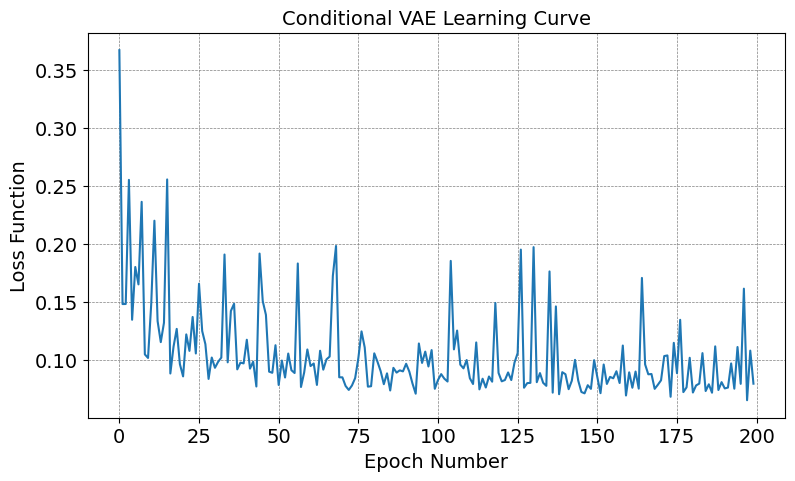

ROC AUC =  0.660523473547685
CPU times: user 2min 41s, sys: 1.66 s, total: 2min 42s
Wall time: 2min 48s


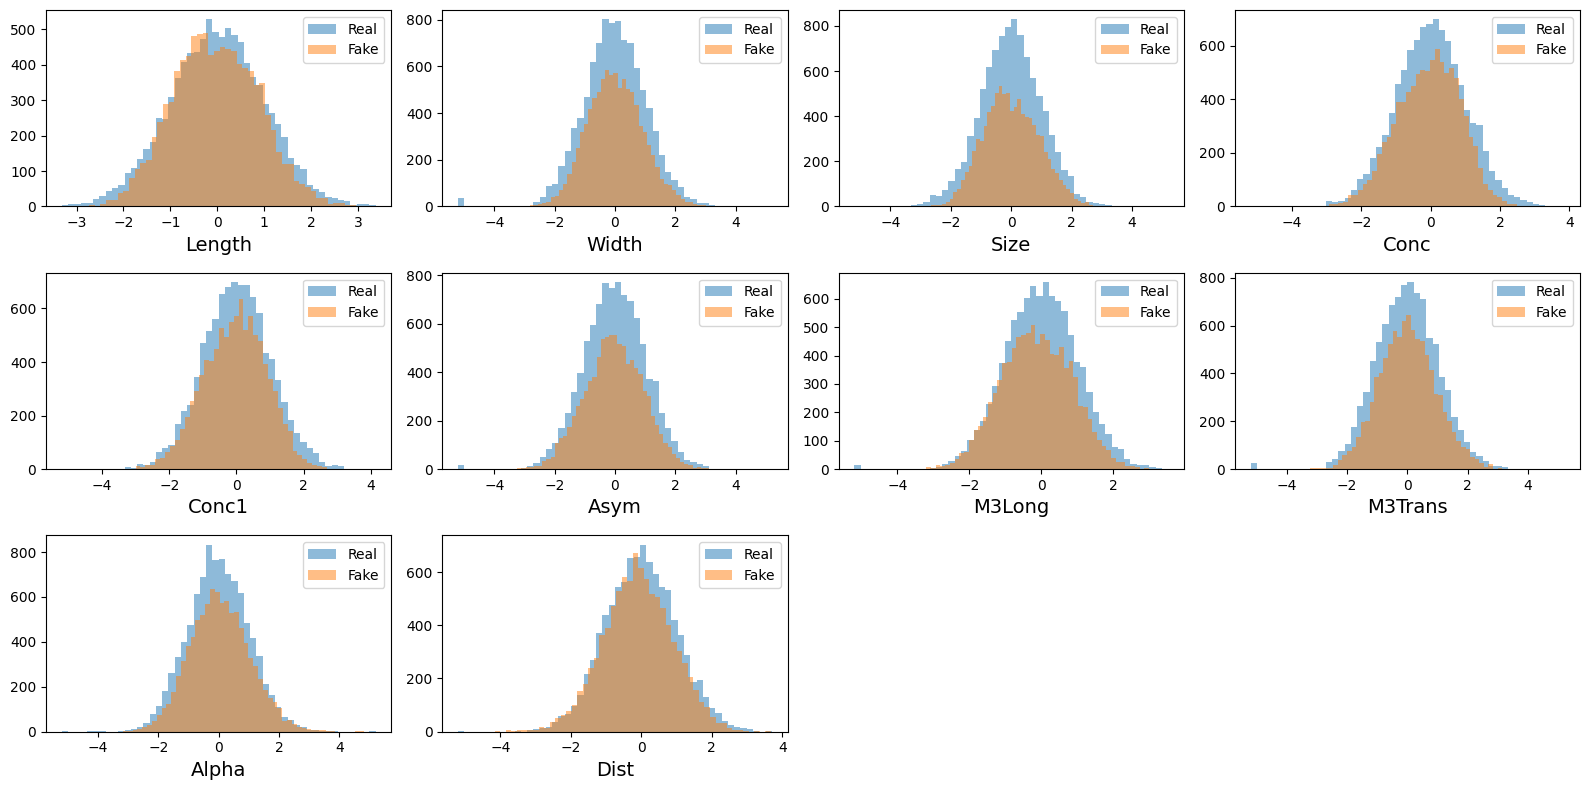

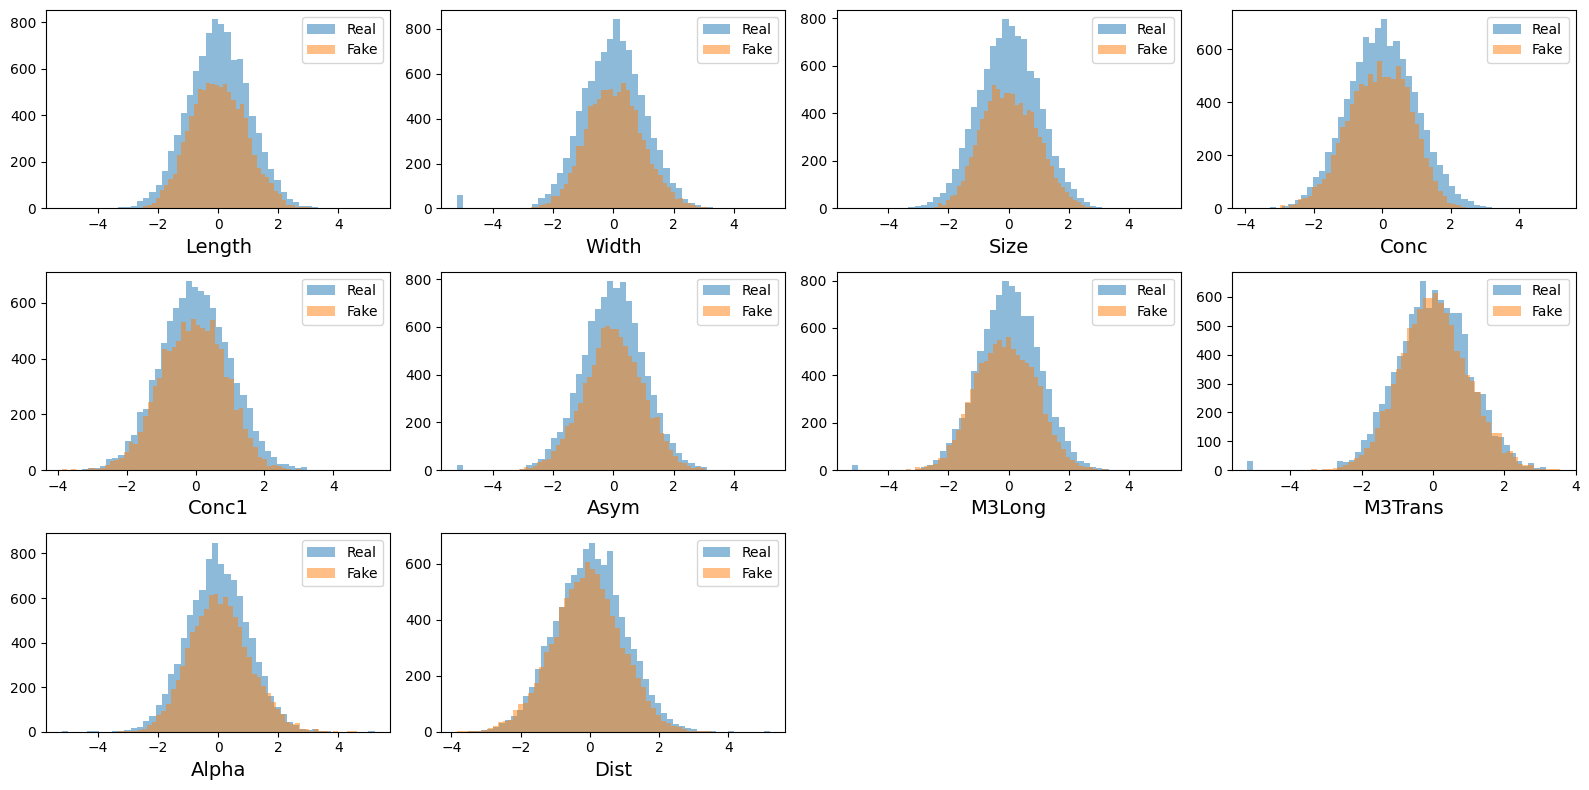

In [62]:
# увеличение количества эпох и lr дало свои плоды
# попробуем увеличить коэффициент KL-регуляризации
%%time
results.append(run_vae_experiment(config={
    'latent_dim': 10,
    'inner_dim': 100,
    'batch_size': 50,
    'n_epochs': 200,
    'lr': 0.002,
    'KL_weight': 0.003
}))

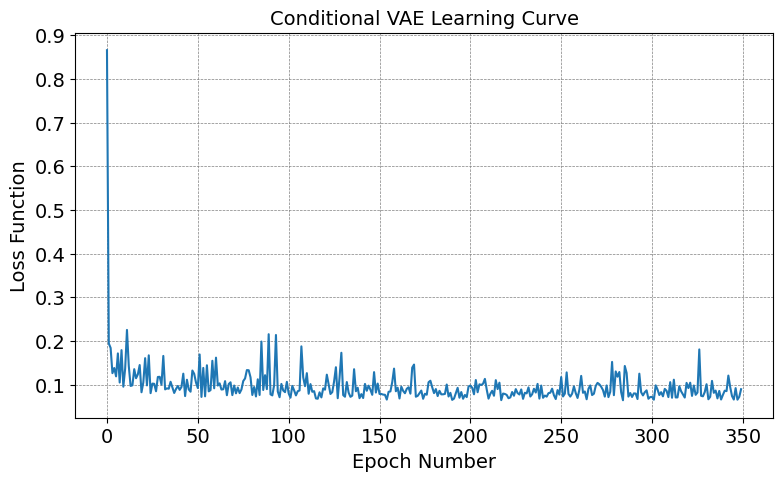

ROC AUC =  0.6513642455061416
CPU times: user 4min 27s, sys: 2.84 s, total: 4min 30s
Wall time: 4min 32s


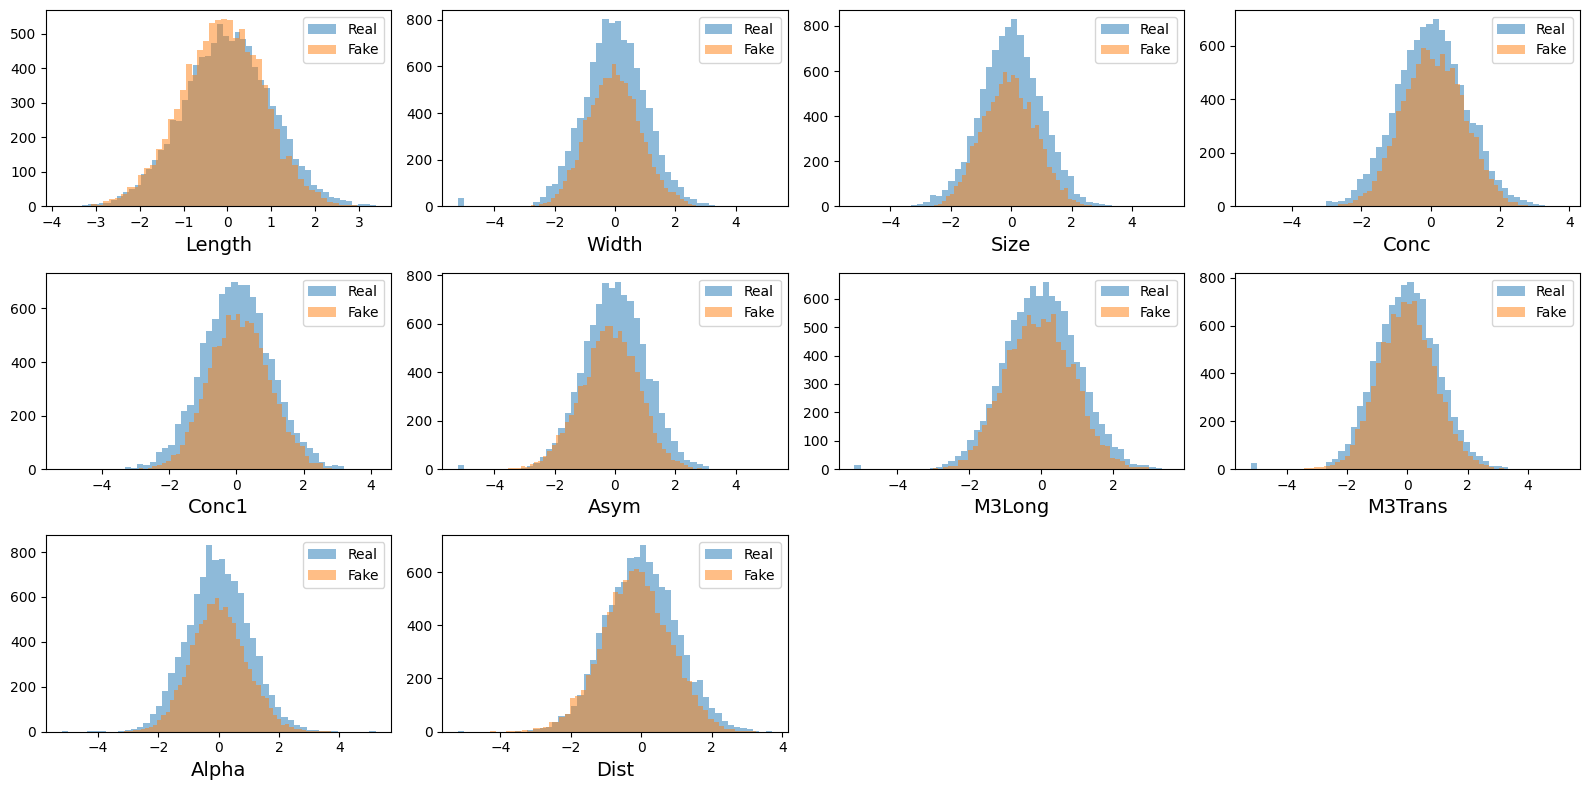

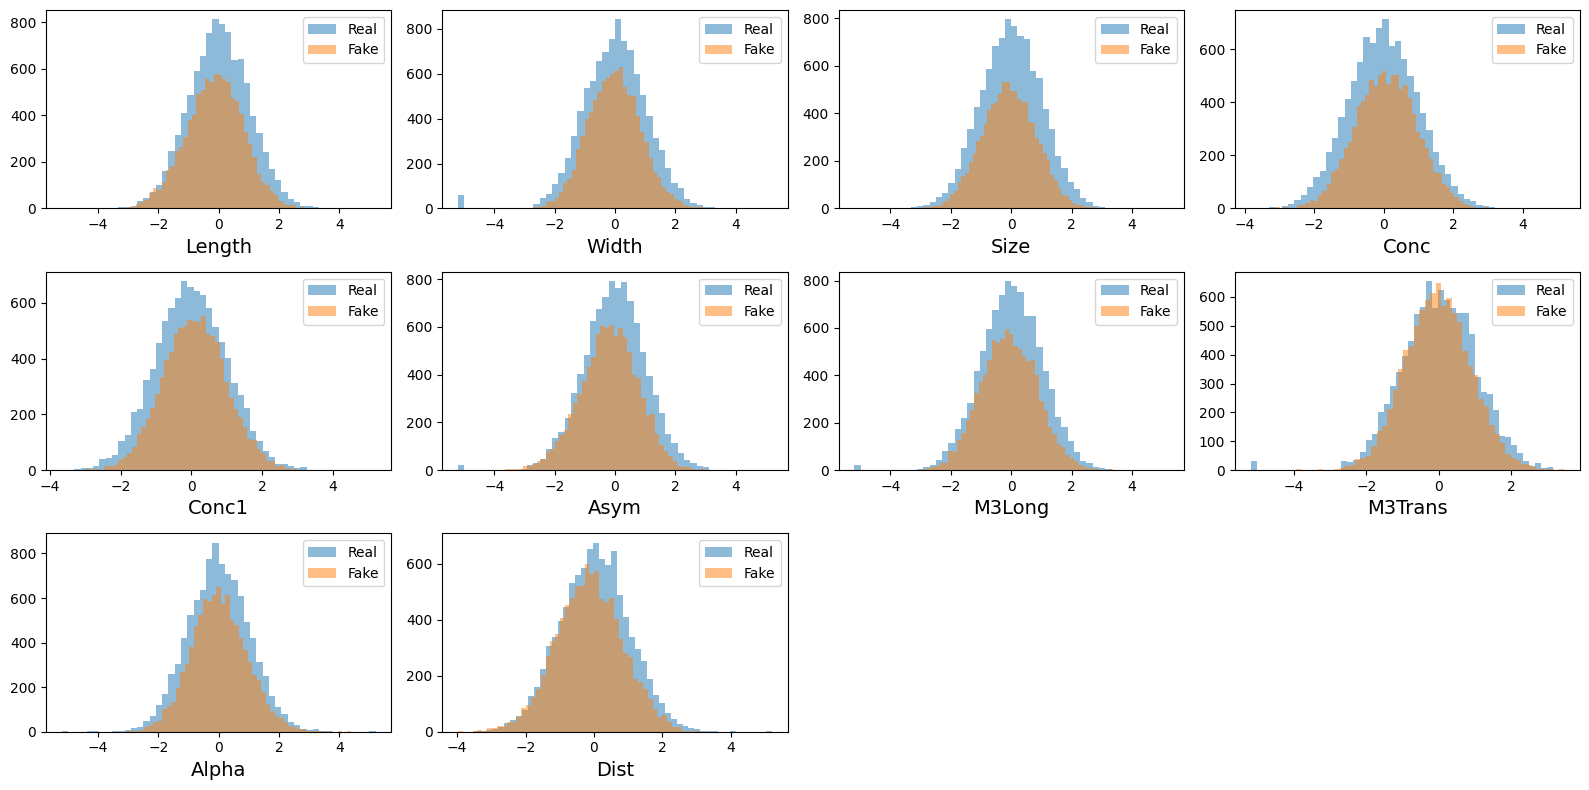

In [63]:
# нам удалось сбросить еще 0.01 от целевой метрики
# по графику видно, что функция потерь постепенно продолжает уменьшаться
# значит мы можем увеличить количество эпох, чтобы выйти на плато по качеству
%%time
results.append(run_vae_experiment(config={
    'latent_dim': 10,
    'inner_dim': 100,
    'batch_size': 50,
    'n_epochs': 350,
    'lr': 0.002,
    'KL_weight': 0.003
}))

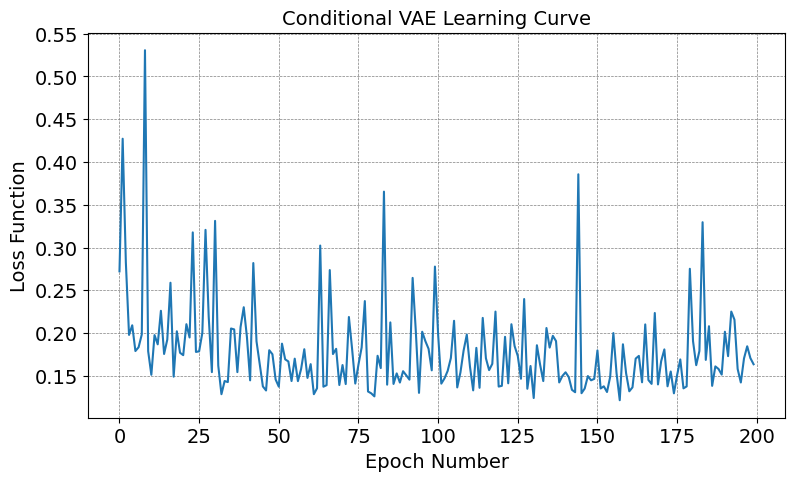

ROC AUC =  0.71918234278821
CPU times: user 2min 37s, sys: 1.73 s, total: 2min 38s
Wall time: 2min 42s


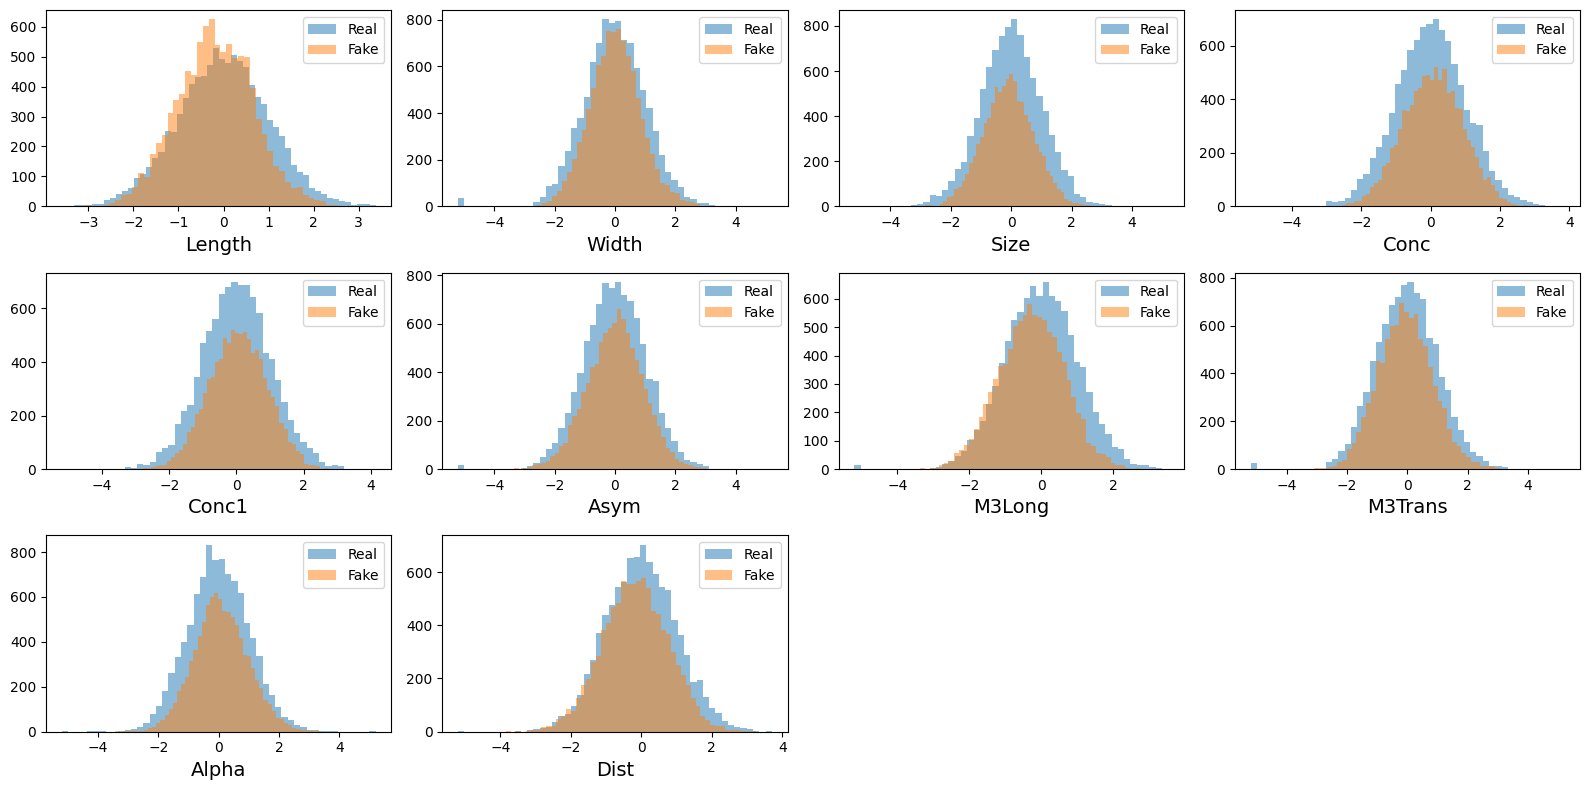

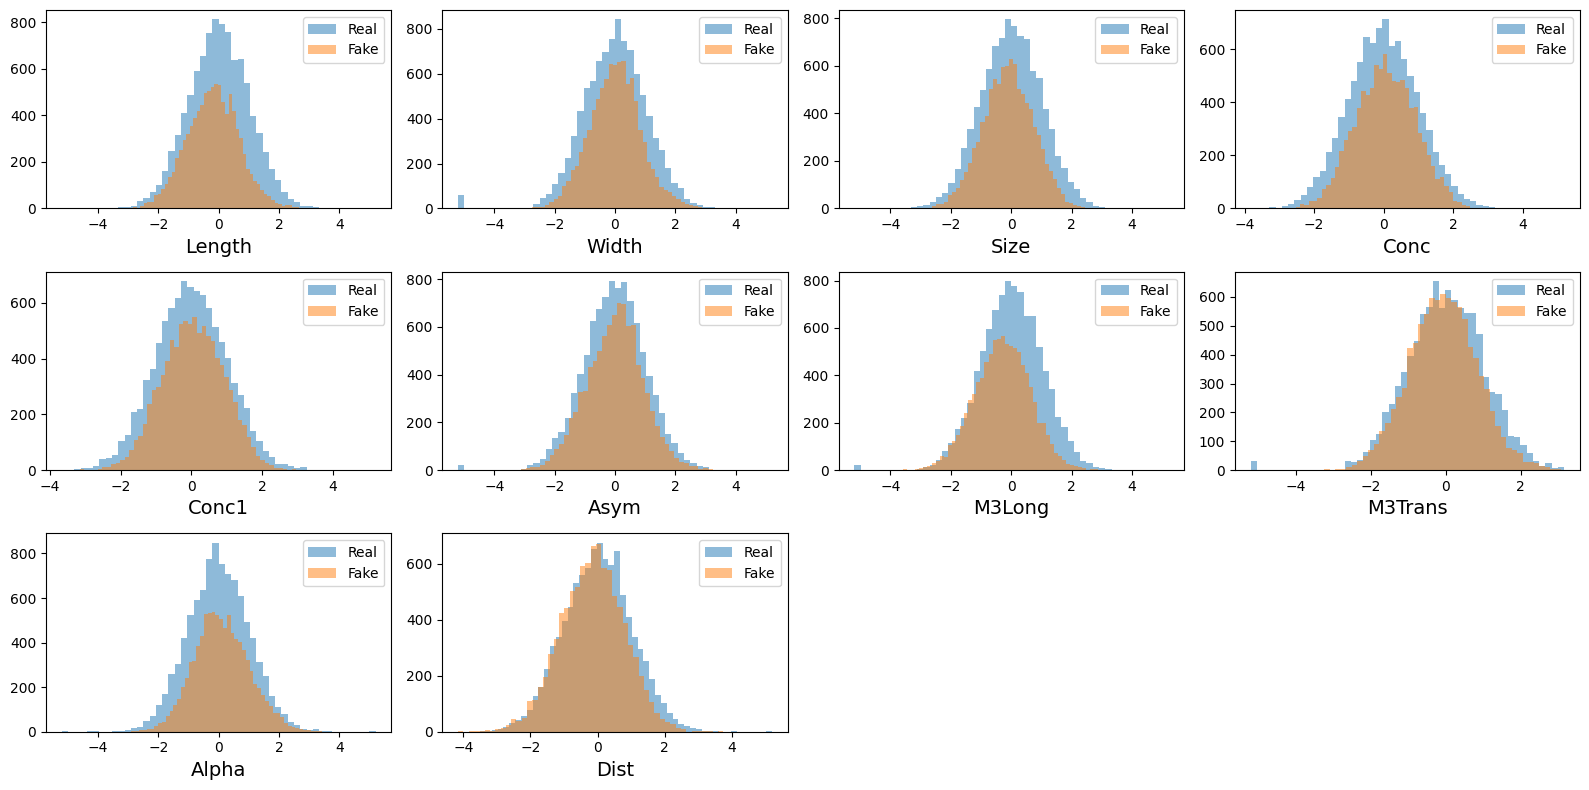

In [64]:
# попробуем экстремальные значения lr и KL
%%time
results.append(run_vae_experiment(config={
    'latent_dim': 10,
    'inner_dim': 100,
    'batch_size': 50,
    'n_epochs': 200,
    'lr': 0.005,
    'KL_weight': 0.007
}))

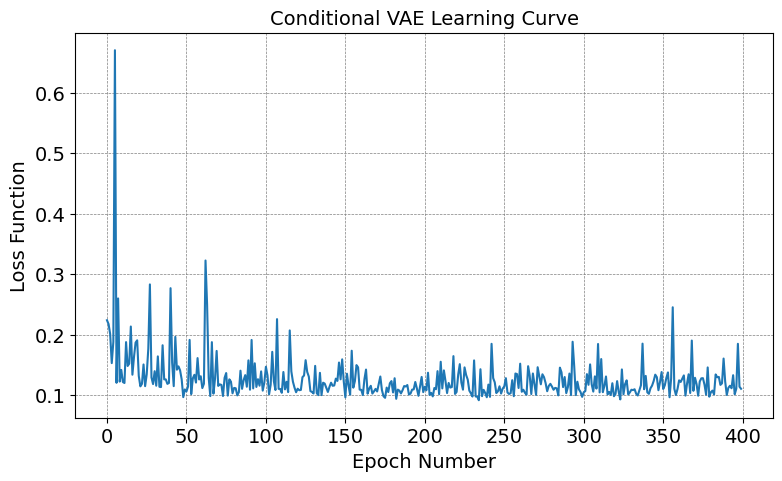

ROC AUC =  0.673710909209521
CPU times: user 5min 1s, sys: 3.17 s, total: 5min 4s
Wall time: 5min 7s


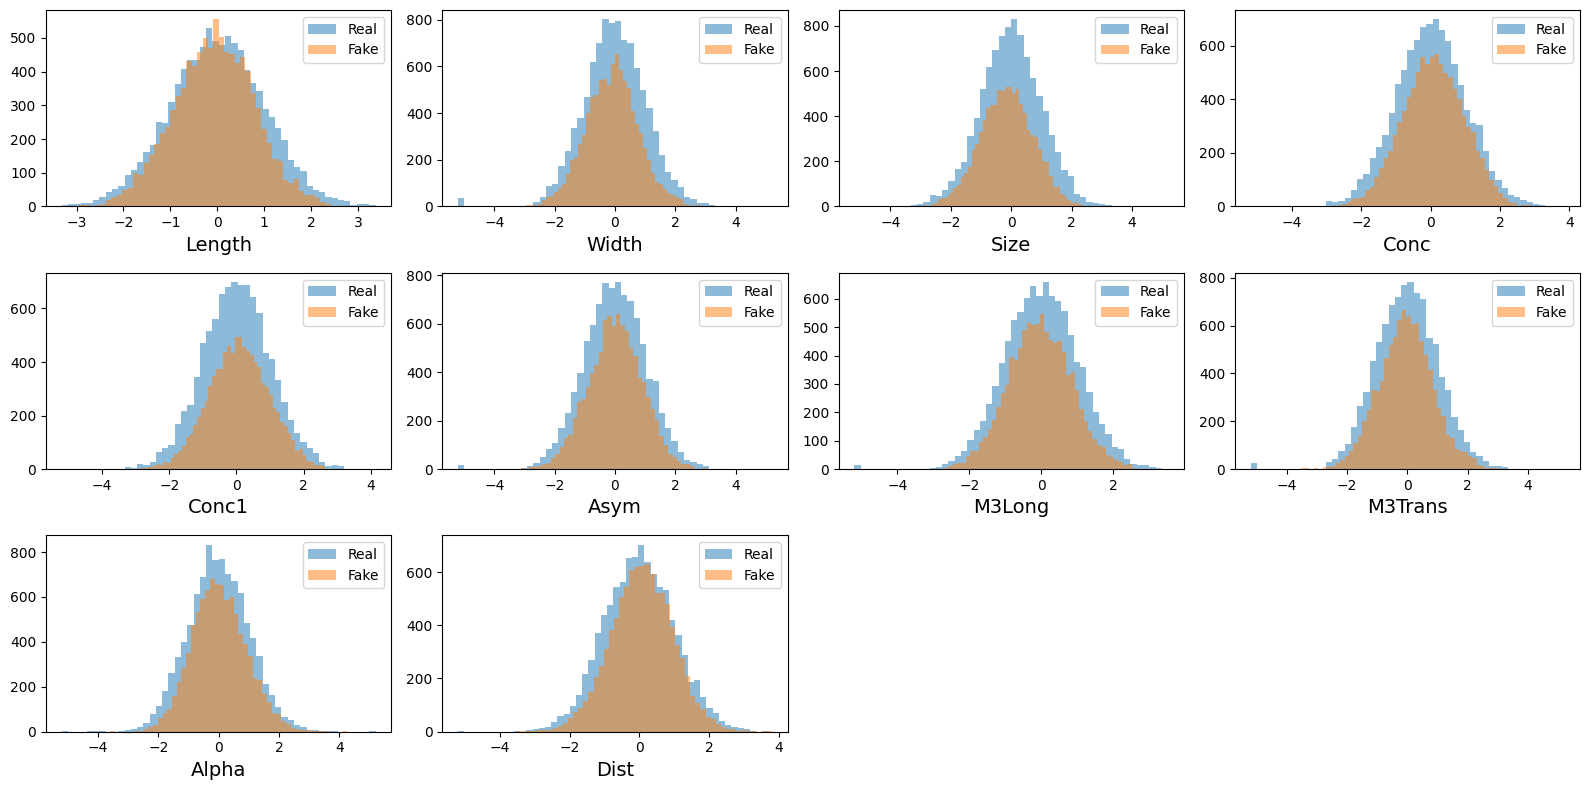

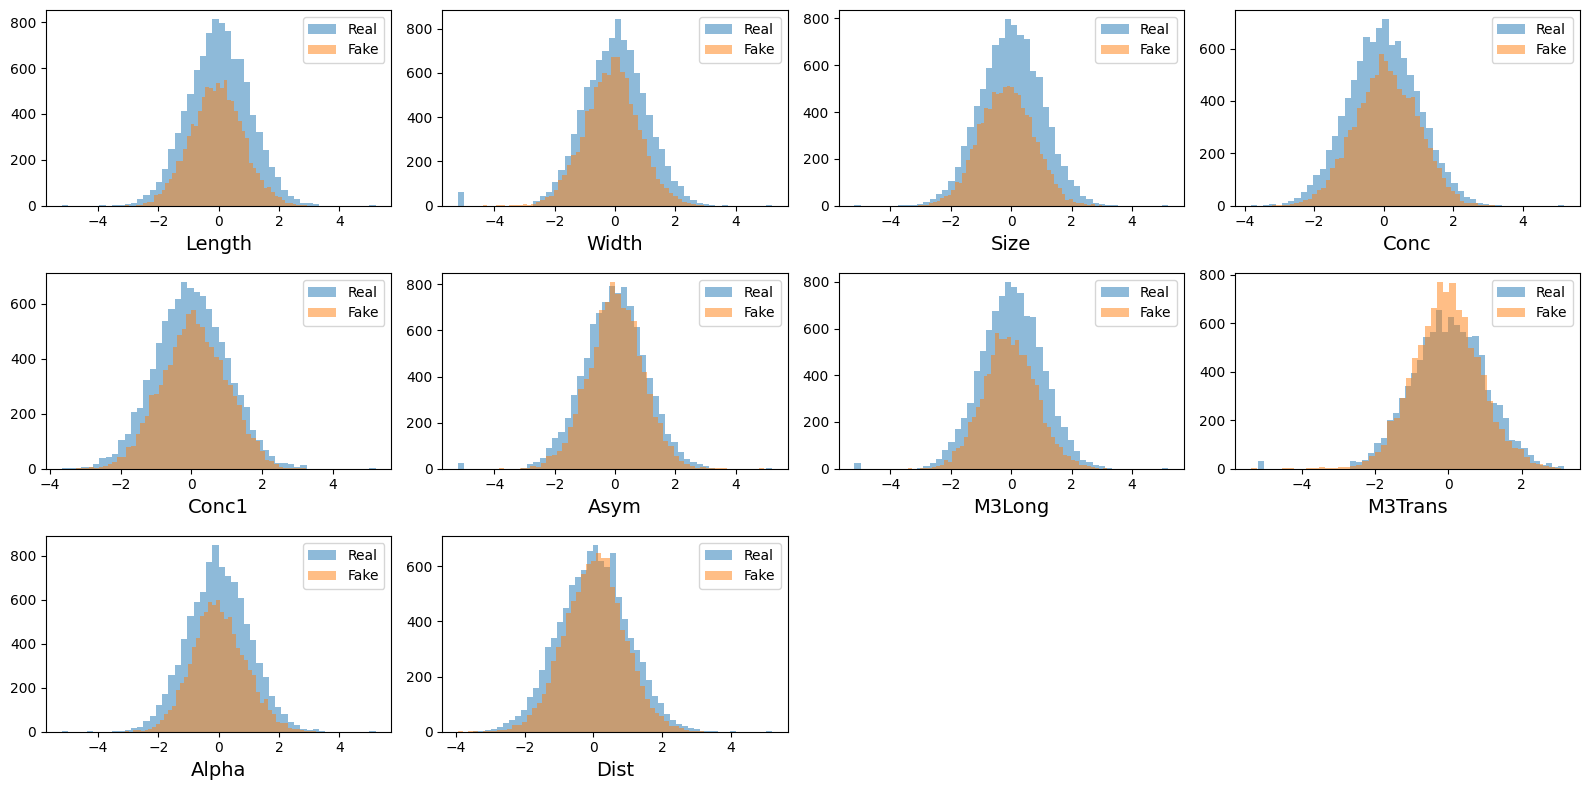

In [65]:
%%time
results.append(run_vae_experiment(config={
    'latent_dim': 10,
    'inner_dim': 100,
    'batch_size': 50,
    'n_epochs': 400,
    'lr': 0.003,
    'KL_weight': 0.005
}))

### Результаты

In [66]:
pd.DataFrame(results)

,latent_dim,inner_dim,batch_size,n_epochs,lr,KL_weight,auc
0,10,150,50,100,0.001,0.001,0.719819
1,10,100,50,100,0.001,0.001,0.717873
2,15,100,50,100,0.001,0.001,0.735704
3,15,150,50,100,0.001,0.001,0.734651
4,10,100,50,200,0.002,0.001,0.677923
5,10,100,50,200,0.002,0.003,0.660523
6,10,100,50,350,0.002,0.003,0.651364
7,10,100,50,200,0.005,0.007,0.719182
8,10,100,50,400,0.003,0.005,0.673711


Итог: лушчий результат для VAE (0.651364) показали параметры n_epochs=350, lr=0.002, KL_weight=0.003.

## WGAN

### Подготовка к эксперименту

In [68]:
class Generator(nn.Module):
    def __init__(self, n_inputs, n_outputs, inner_dim=100):
        super(Generator, self).__init__()

        self.net = nn.Sequential(
            nn.Linear(n_inputs, inner_dim),
            nn.BatchNorm1d(inner_dim),
            nn.ReLU(),
            nn.Linear(inner_dim, inner_dim),
            nn.BatchNorm1d(inner_dim),
            nn.ReLU(),
            nn.Linear(inner_dim, n_outputs)
        )

    def forward(self, z, y):
        zy = torch.cat((z, y), dim=1)
        return self.net(zy)

class Discriminator(nn.Module):
    def __init__(self, n_inputs, inner_dim=100):
        super(Discriminator, self).__init__()


        self.net = nn.Sequential(
            nn.Linear(n_inputs, inner_dim),
            nn.ReLU(),
            nn.Linear(inner_dim, inner_dim),
            nn.ReLU(),
            nn.Linear(inner_dim, 1)
        )


    def forward(self, x, y):
        xy = torch.cat((x, y), dim=1)
        return self.net(xy)

In [69]:
def eval_roc_auc(X_train, X_fake_train, X_test, X_fake_test):
  XX_train = np.concatenate((X_fake_train, X_train), axis=0)
  XX_test = np.concatenate((X_fake_test, X_test), axis=0)

  yy_train = np.array([0] * len(X_fake_train) + [1] * len(X_train))
  yy_test = np.array([0] * len(X_fake_test) + [1] * len(X_test))
  clf = GradientBoostingClassifier()
  clf.fit(XX_train, yy_train)

  yy_test_proba = clf.predict_proba(XX_test)[:, 1]
  auc = roc_auc_score(yy_test, yy_test_proba)
  print("ROC AUC = ", auc)
  return auc

def generate(generator, y, latent_dim):
    y = torch.tensor(y, dtype=torch.float, device=DEVICE)
    Z_noise = torch.normal(0, 1, (len(y), latent_dim)).to(DEVICE)
    with torch.no_grad():
        X_fake = generator(Z_noise, y)
    X_fake = X_fake.cpu().numpy()
    return X_fake



def run_wgan_experiment(config):
  latent_dim = config['latent_dim']
  generator = Generator(n_inputs=latent_dim + y.shape[1],
                        n_outputs=X_train.shape[1],
                        inner_dim=config['inner_dim'])
  discriminator = Discriminator(n_inputs=X_train.shape[1] + y.shape[1],
                                inner_dim=config['inner_dim'])

  fitter = Fitter(
      generator,
      discriminator,
      batch_size=config['batch_size'],
      n_epochs=config['n_epochs'],
      latent_dim=latent_dim,
      lr=config['lr'],
      n_critic=config['n_critic'],
  )
  fitter.fit(X_train, y_train)


  plt.figure(figsize=(9, 5))
  plt.plot(fitter.loss_history)
  plt.xlabel("Epoch Number", size=14)
  plt.ylabel("Loss Function", size=14)
  plt.xticks(size=14)
  plt.yticks(size=14)
  plt.title("Conditional WGAN Learning Curve", size=14)
  plt.grid(visible=True, linestyle="--", linewidth=0.5, color="0.5")
  plt.show()


  X_fake_train = generate(fitter.generator, y_train, latent_dim)
  plot_hists(X_train, X_fake_train, names, label1="Real", label2="Fake", bins=50)
  X_fake_test = generate(fitter.generator, y_test, latent_dim)
  plot_hists(X_test, X_fake_test, names, label1="Real", label2="Fake", bins=50)

  # evaluate fake data
  auc = eval_roc_auc(X_train, X_fake_train, X_test, X_fake_test)

  result = config.copy()
  result['auc'] = auc
  return result

In [70]:
import random
import numpy as np
import torch

seed = 42

random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)

base_config={
    'latent_dim': 10,
    'inner_dim': 100,
    'batch_size': 50,
    'n_epochs': 100,
    'lr': 0.0001,
    'n_critic': 5
}

results_wgan=[
  {
  'latent_dim': 10,
  'inner_dim': 100,
  'batch_size': 50,
  'n_epochs': 100,
  'lr': 0.0001,
  'n_critic': 5,
  'auc': np.float64(0.7302721525075713)
  }
]

### Эксперименты

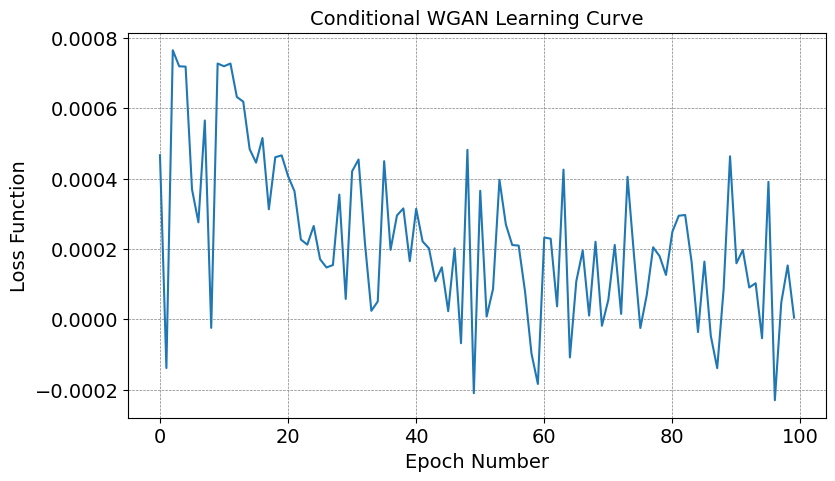

ROC AUC =  0.6900446704503865
CPU times: user 1min 24s, sys: 665 ms, total: 1min 24s
Wall time: 1min 26s


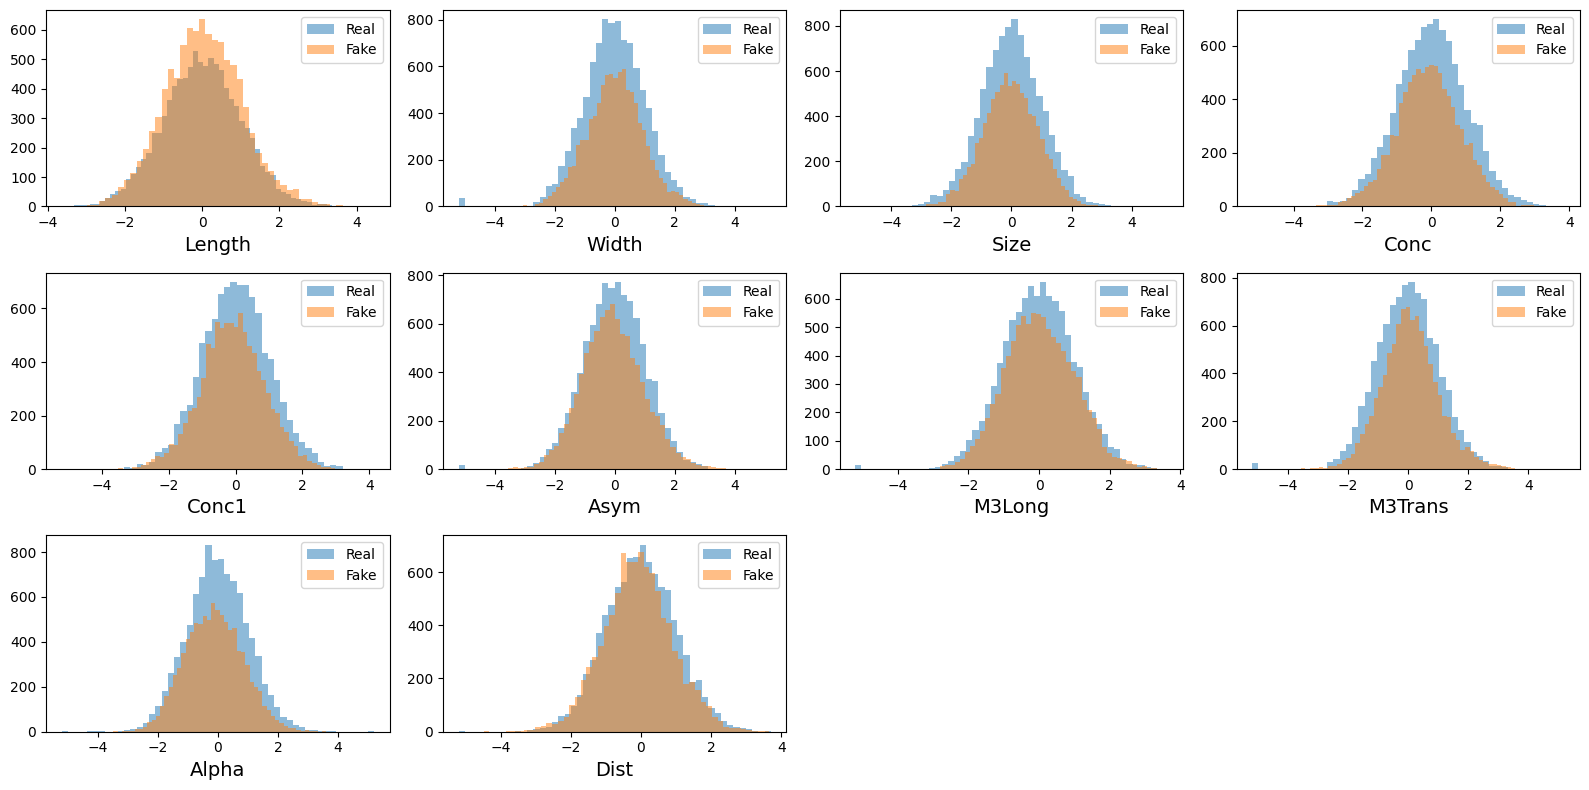

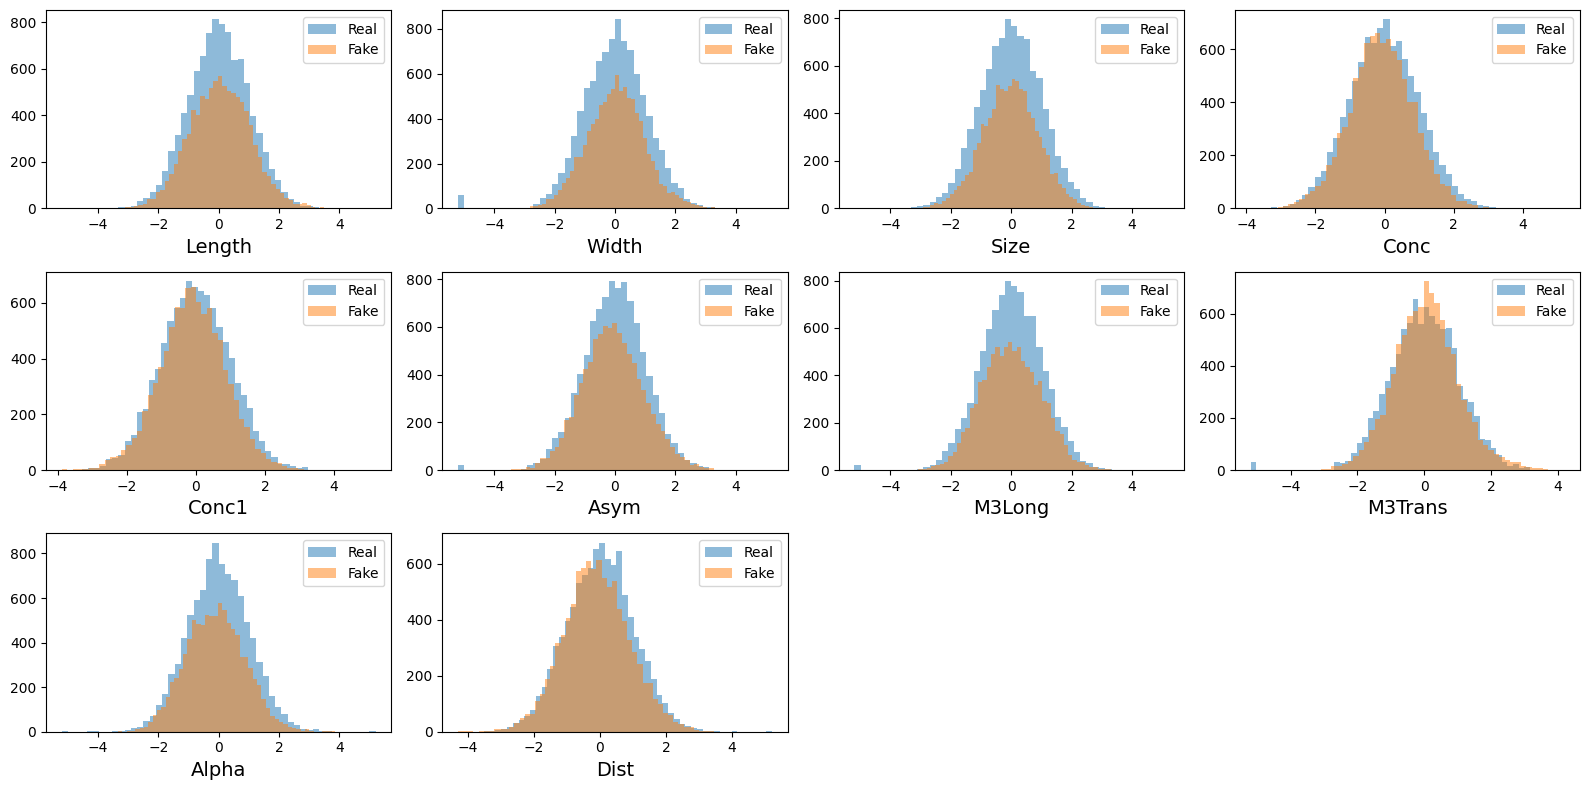

In [73]:
# сначала поэкспериментируем с архитектурой
%%time
results_wgan.append(run_wgan_experiment(config={
    'latent_dim': 20, # увеличил в 2 раза, по сравнению с базовым конфигом
    'inner_dim': 200,
    'batch_size': 50,
    'n_epochs': 100,
    'lr': 0.0001,
    'n_critic': 5
}))

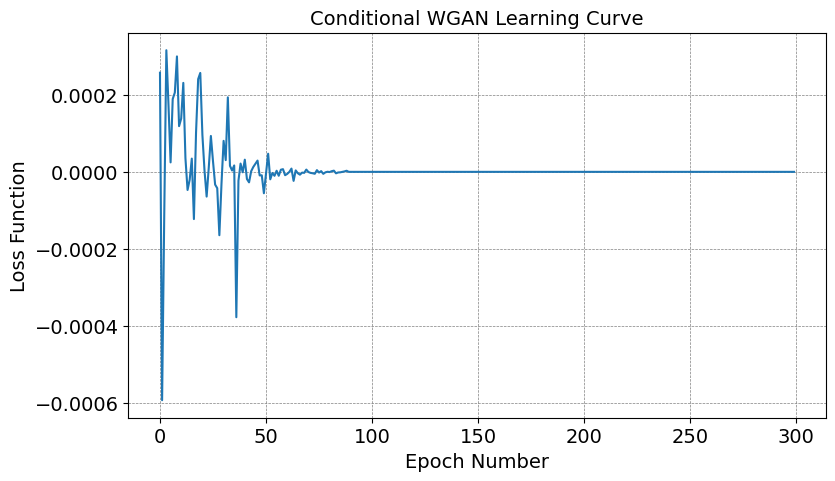

ROC AUC =  0.7271757218313558
CPU times: user 3min 38s, sys: 2.1 s, total: 3min 40s
Wall time: 3min 43s


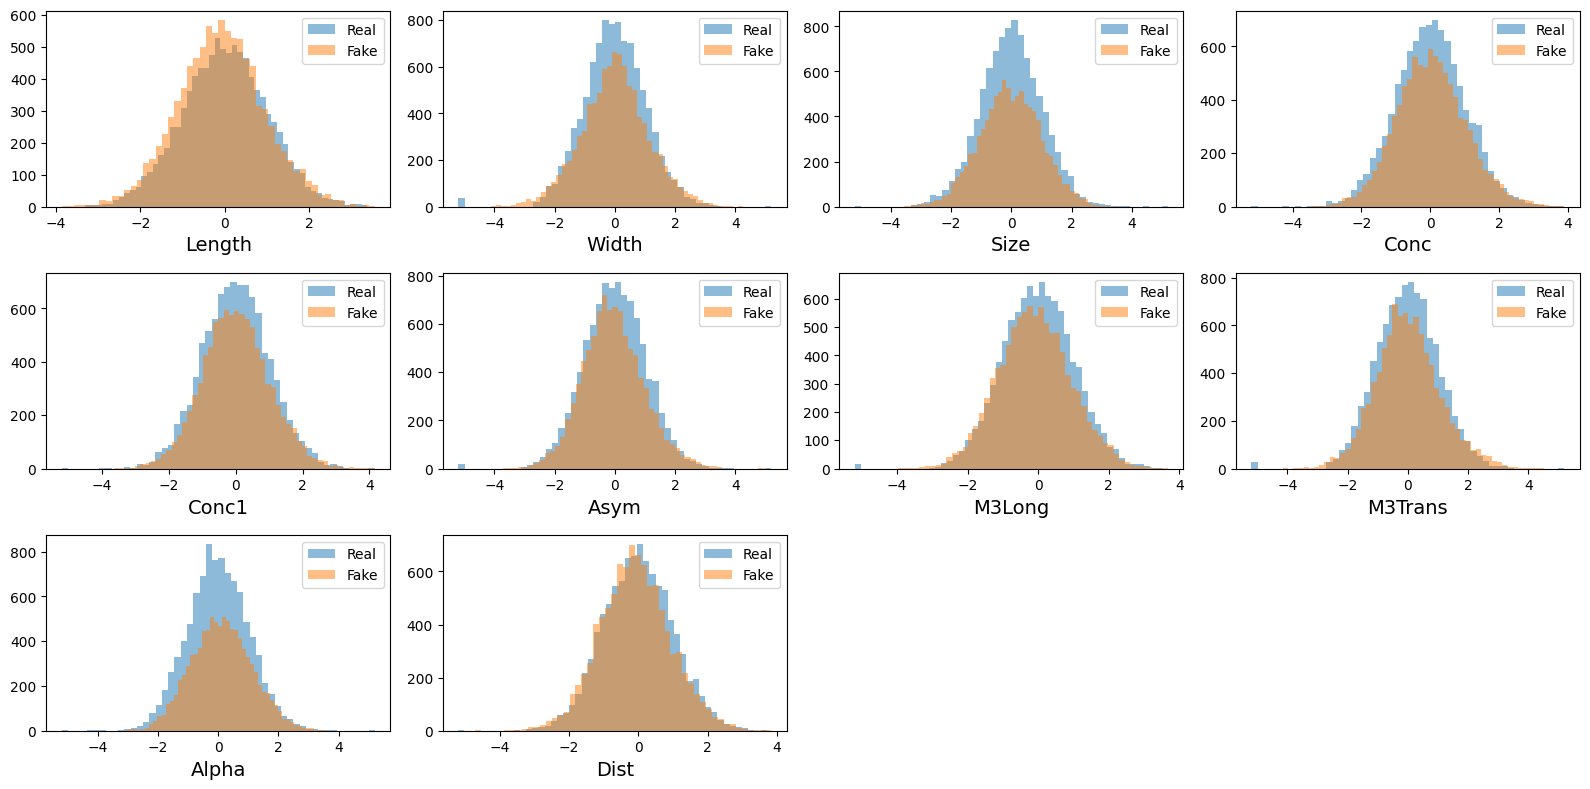

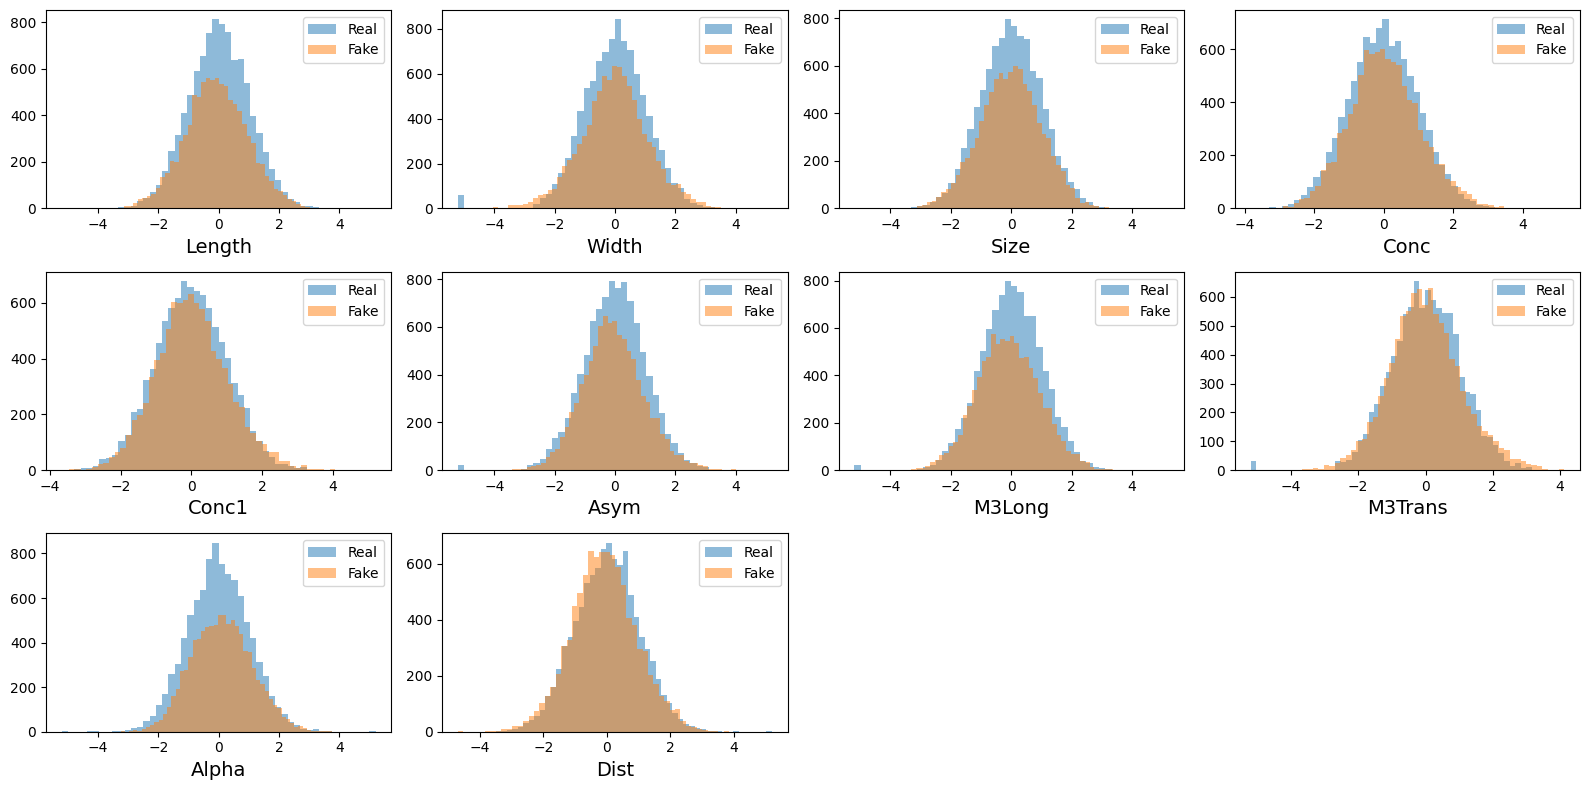

In [74]:
# в отличие от VAE, изменение архитектуры для WGAN полжоительно повлияло на целевую метрику
# попробуем увеличить также и параметры обучения
%%time
results_wgan.append(run_wgan_experiment(config={
    'latent_dim': 20,
    'inner_dim': 200,
    'batch_size': 50,
    'n_epochs': 300,
    'lr': 0.0003,
    'n_critic': 5
}))

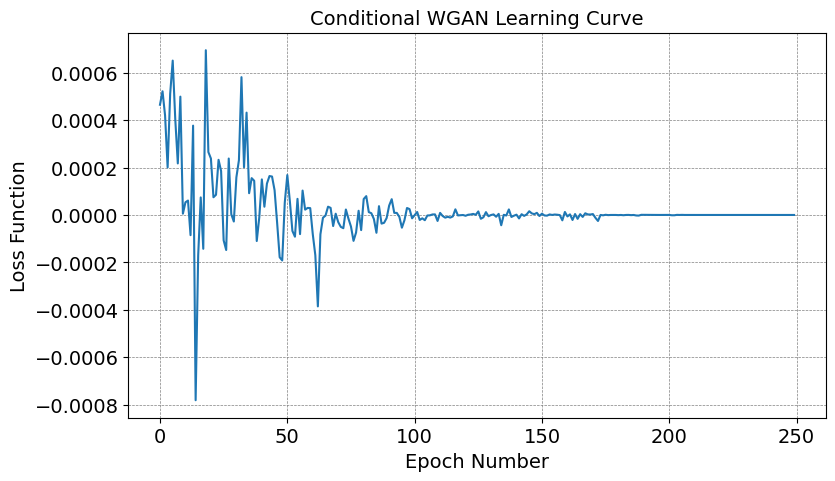

ROC AUC =  0.7853077230122478
CPU times: user 3min 6s, sys: 2.03 s, total: 3min 8s
Wall time: 3min 10s


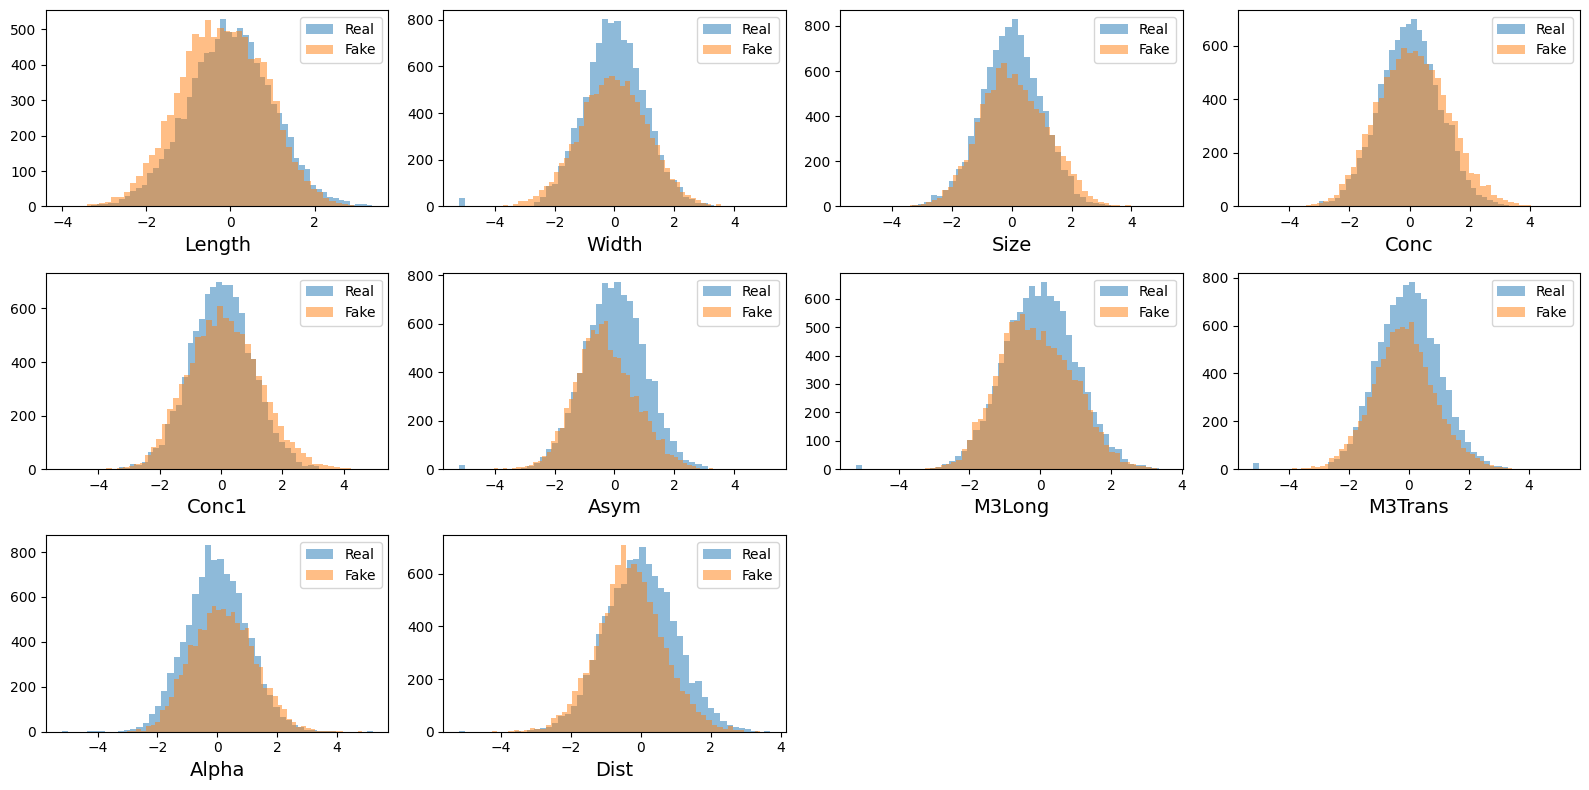

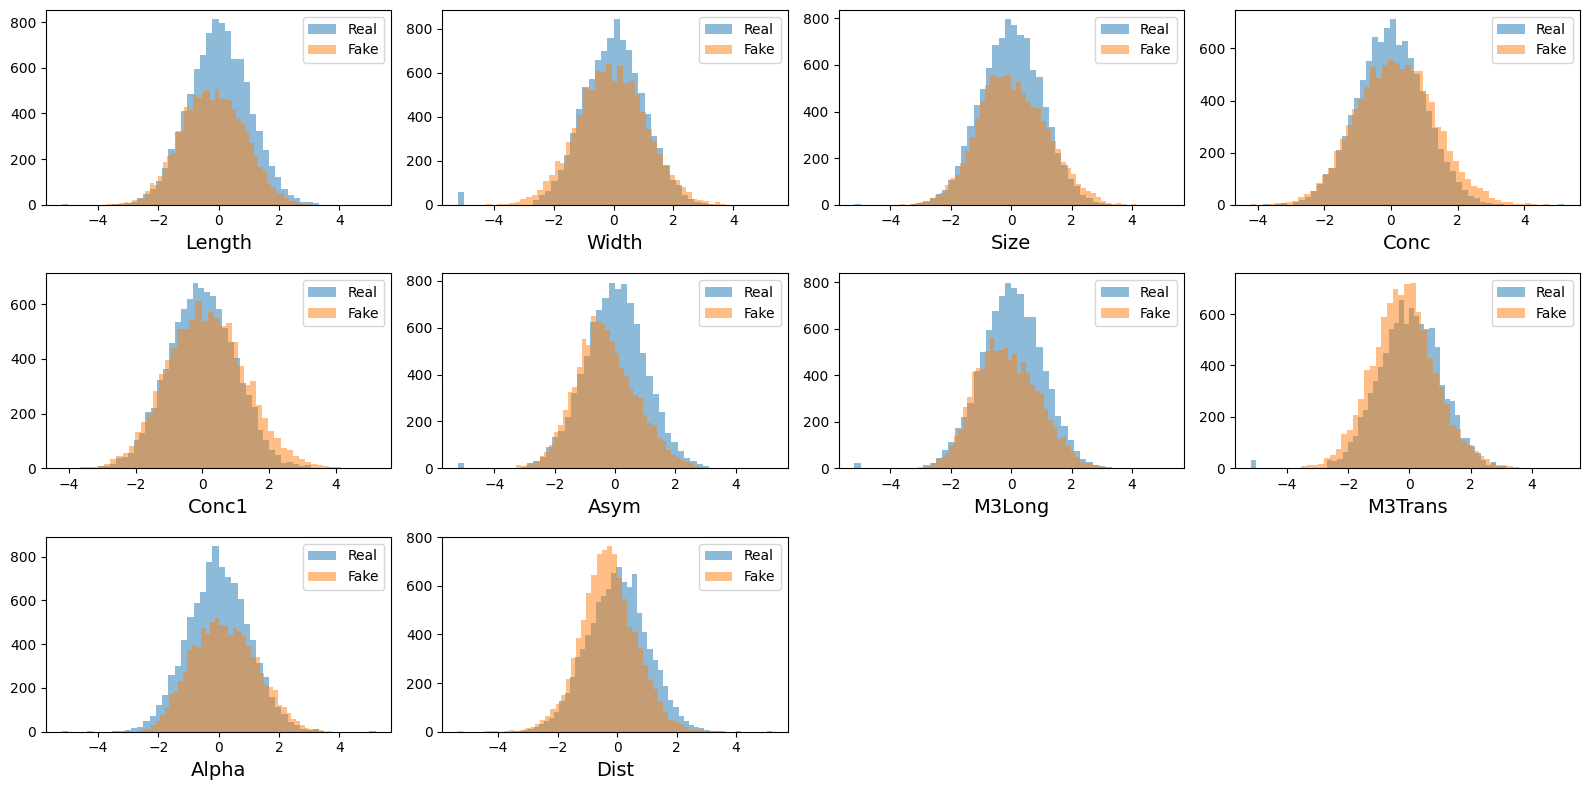

In [75]:
# увеличение lr сломало обучение, попробуем поставить lr меньше
%%time
results_wgan.append(run_wgan_experiment(config={
    'latent_dim': 20,
    'inner_dim': 200,
    'batch_size': 50,
    'n_epochs': 250,
    'lr': 0.0002,
    'n_critic': 5
}))

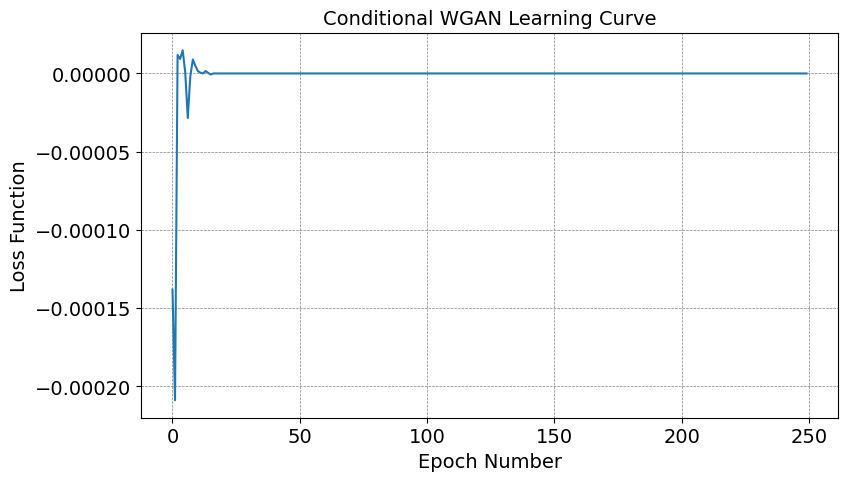

ROC AUC =  0.7587269916773643
CPU times: user 3min 6s, sys: 1.94 s, total: 3min 8s
Wall time: 3min 10s


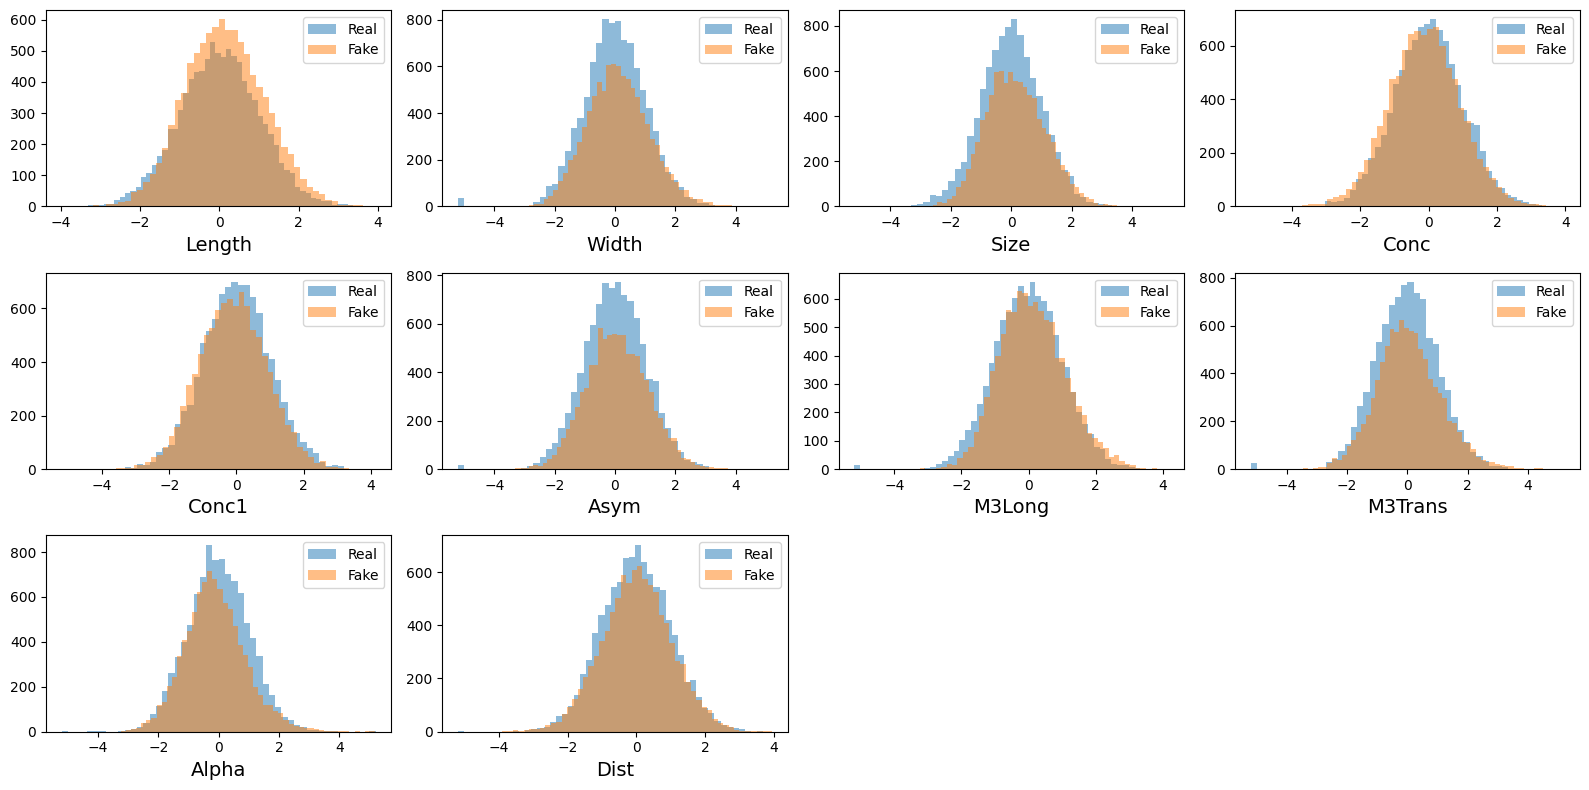

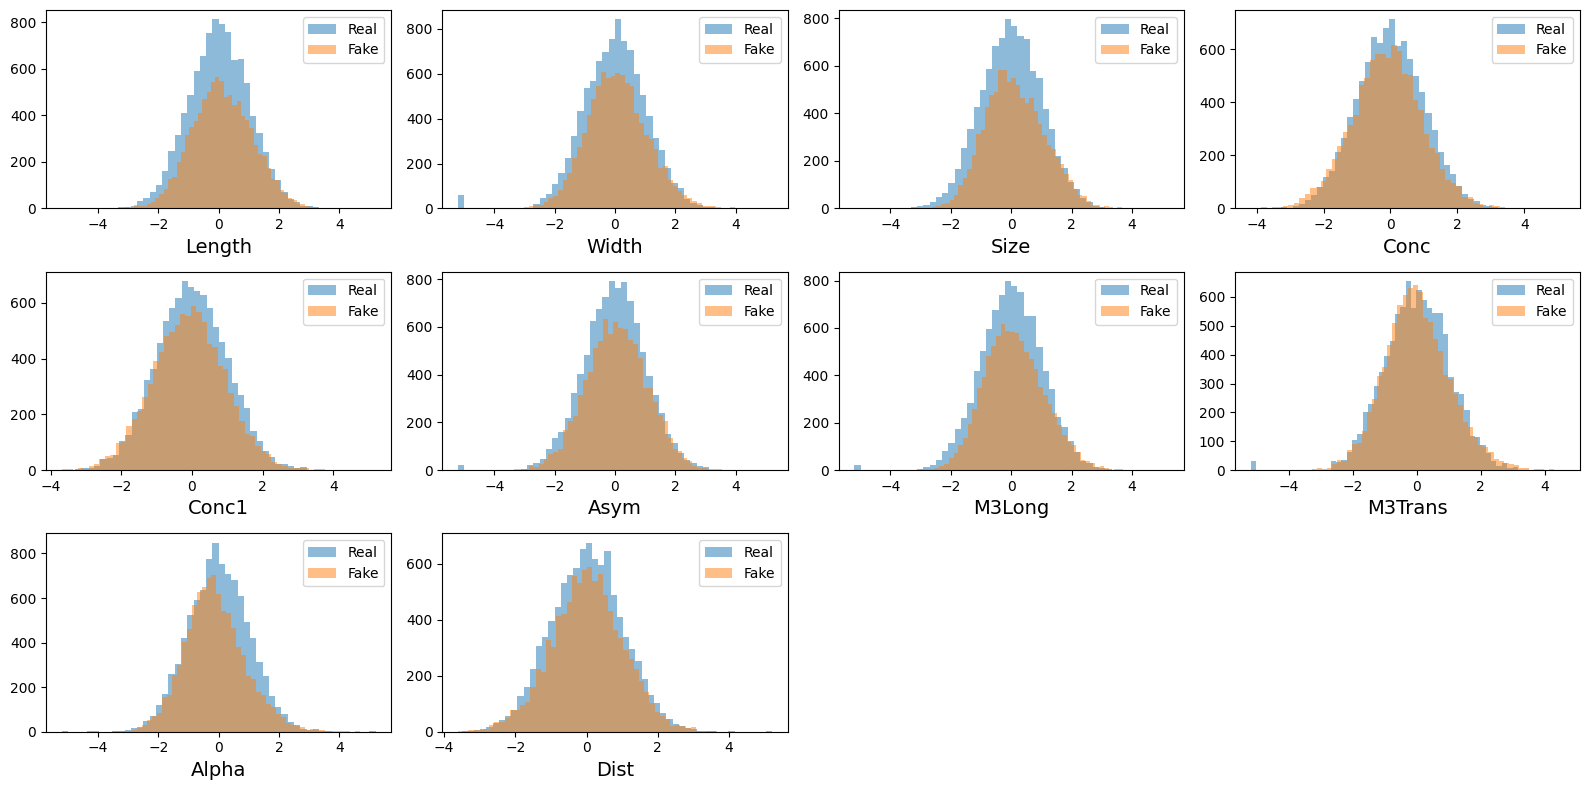

In [76]:
# возможно, странность обучения связана с изменением архитектуры
# вернем архитектуру в оригинальное состояие и изменим параметры
%%time
results_wgan.append(run_wgan_experiment(config={
    'latent_dim': 10,
    'inner_dim': 100,
    'batch_size': 50,
    'n_epochs': 250,
    'lr': 0.001,
    'n_critic': 5
}))

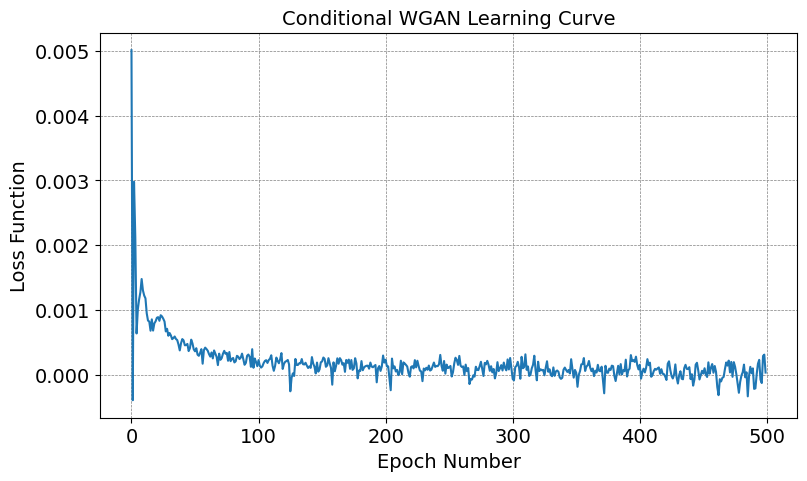

ROC AUC =  0.7007443987788603
CPU times: user 6min 5s, sys: 3.7 s, total: 6min 9s
Wall time: 6min 26s


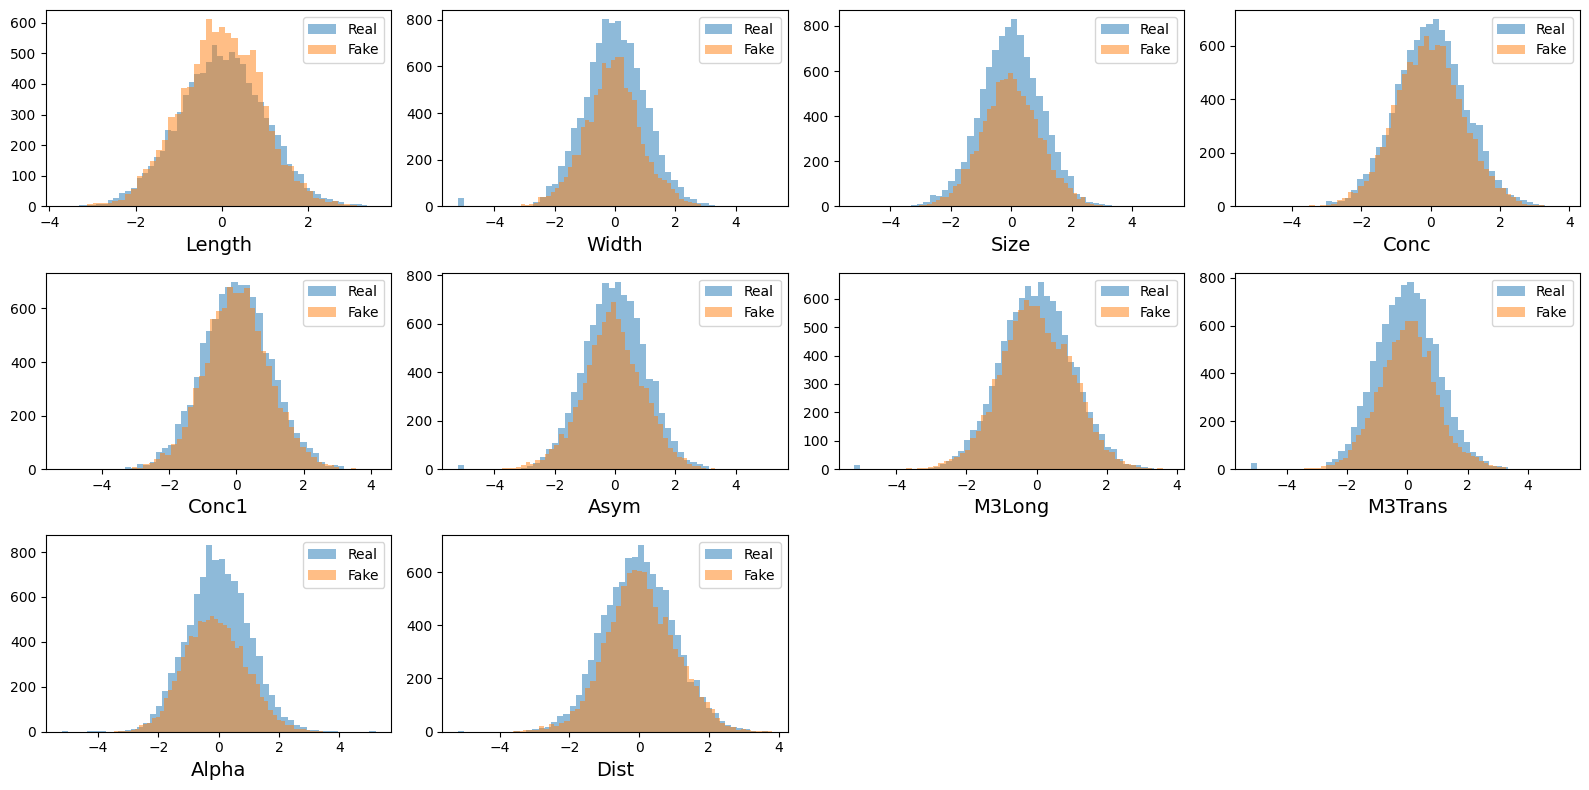

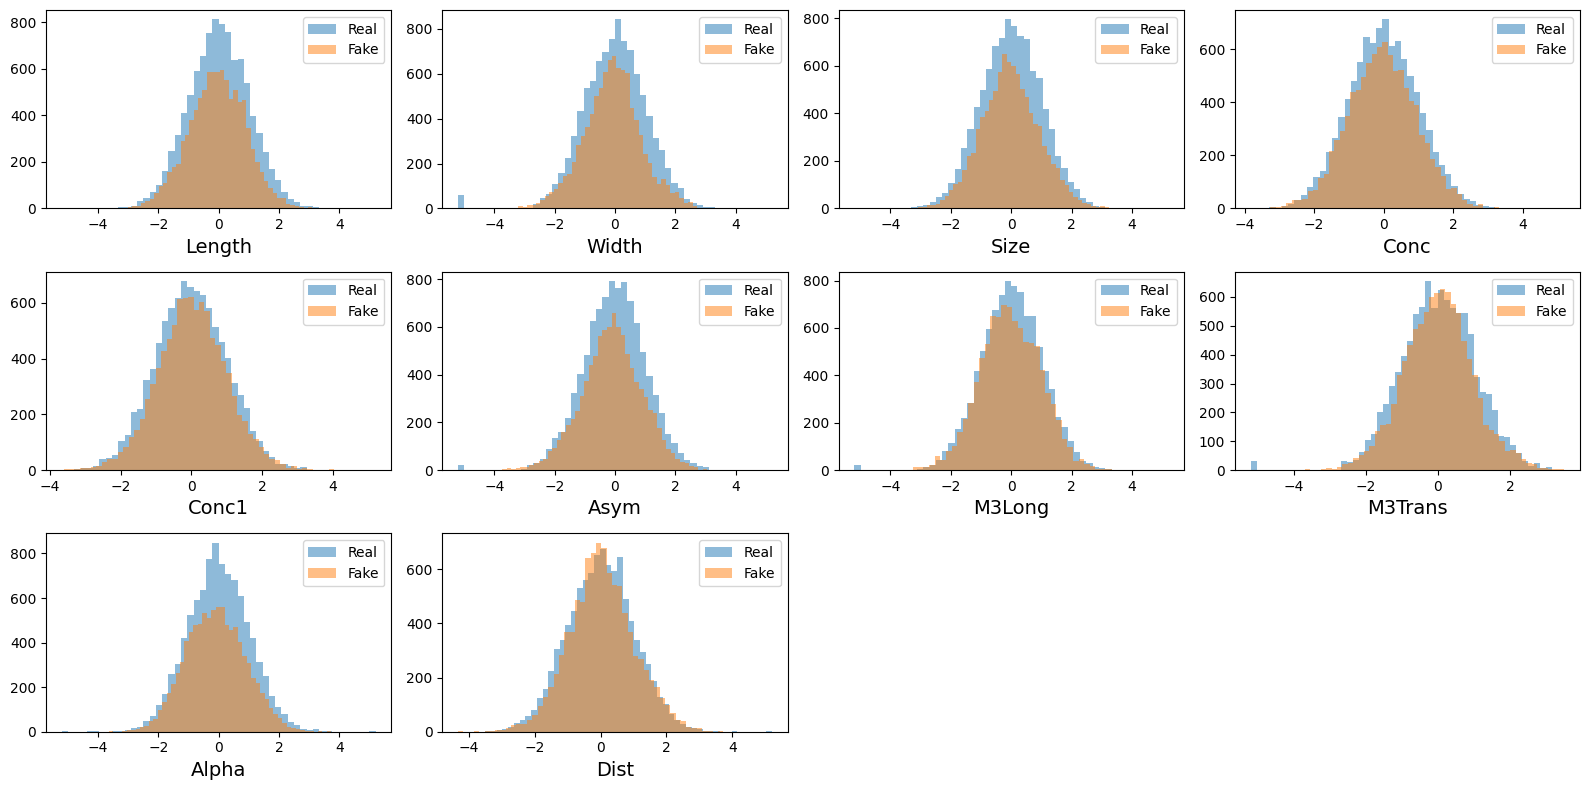

In [77]:
# видимо, ошибки в обучении связаны все же с lr
# поставлю новую архитектуру, маленький lr и много эпох
%%time
results_wgan.append(run_wgan_experiment(config={
    'latent_dim': 20,
    'inner_dim': 200,
    'batch_size': 50,
    'n_epochs': 500,
    'lr': 0.00005,
    'n_critic': 5
}))

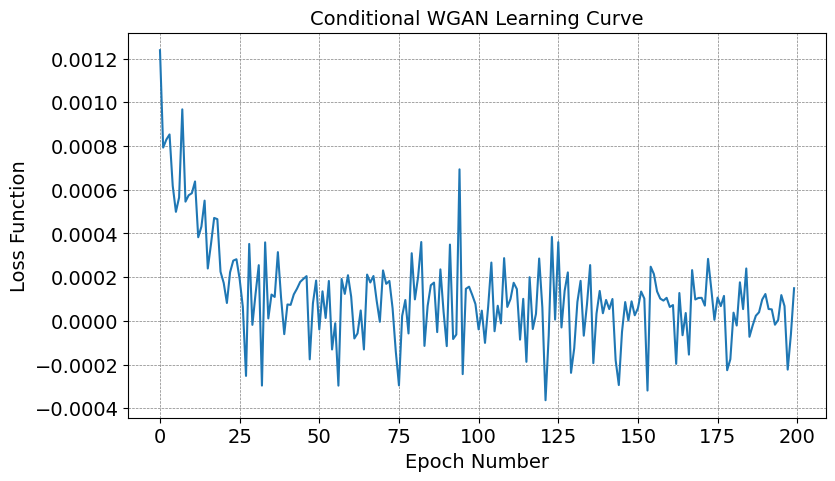

ROC AUC =  0.7163585290153371
CPU times: user 2min 28s, sys: 1.18 s, total: 2min 29s
Wall time: 2min 30s


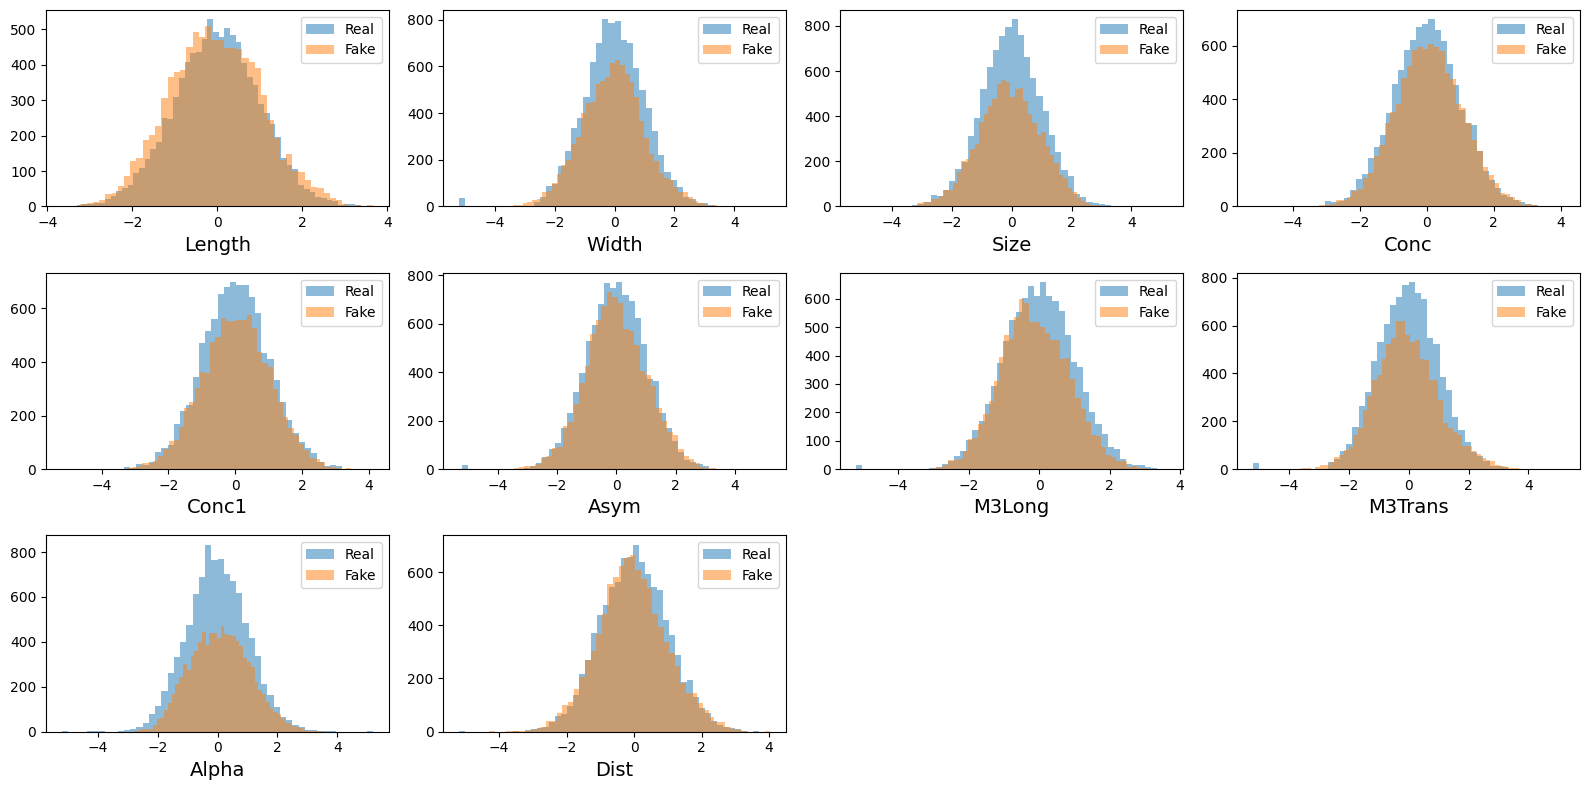

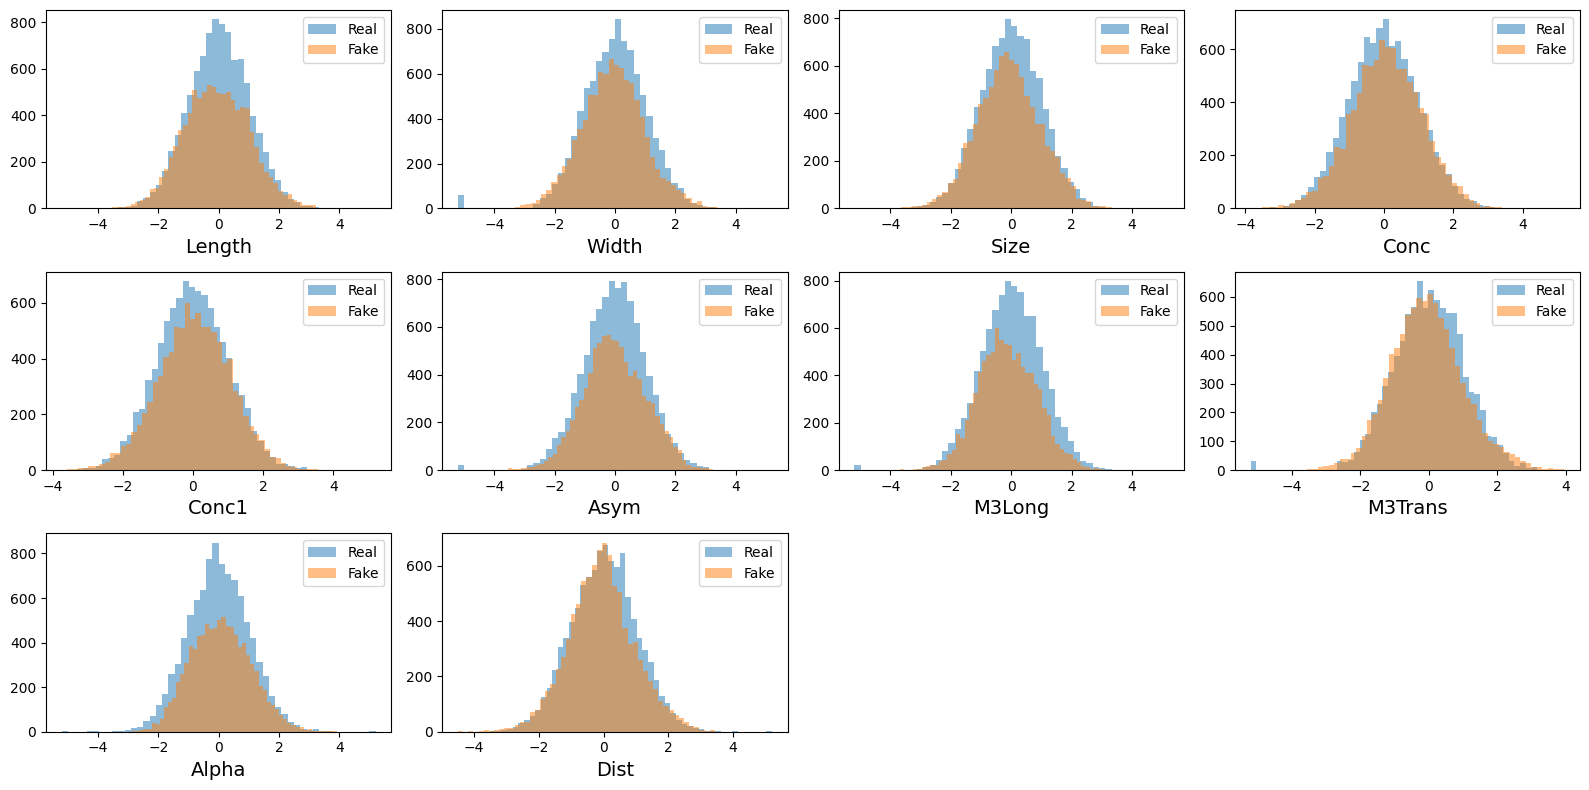

In [79]:
# видимо, ошибки в обучении связаны все же с lr
# поставлю новую архитектуру, маленький lr и много эпох
%%time
results_wgan.append(run_wgan_experiment(config={
    'latent_dim': 20,
    'inner_dim': 200,
    'batch_size': 50,
    'n_epochs': 200,
    'lr': 0.0001,
    'n_critic': 5
}))

### Результаты

In [80]:
pd.DataFrame(results_wgan)

,latent_dim,inner_dim,batch_size,n_epochs,lr,n_critic,auc
0,10,100,50,100,0.00010,5,0.730272
1,20,200,50,100,0.00010,5,0.690045
2,20,200,50,300,0.00030,5,0.727176
3,20,200,50,250,0.00020,5,0.785308
4,10,100,50,250,0.00100,5,0.758727
5,20,200,50,500,0.00005,5,0.700744
6,20,200,50,200,0.00010,5,0.716359


Итог: лушчий результат для WGAN (0.690045) показали параметры latent_dim=20, inner_dim=200, n_epochs=100, lr=0.0001, n_critic=5.

Итог: лучший результат (0.651364) показал архитектура VAE